# NB05: Real Hydrosphere and Pedosphere

This notebook runs RELIC hydrosphere and pedosphere Functors on small hand-built states. You will learn:

1. How the bucket model (`BucketSoilMoisture`) splits precipitation into evapotranspiration, saturation-excess runoff, drainage above field capacity, and storage change
2. How first-order multi-pool soil carbon decomposition (`FirstOrderDecomposition`) responds to temperature and moisture, and how `CarbonPoolsFunctor` reports the pool total
3. What the isotope subpackage provides today (candidate configuration, fractionation calculators, and a fail-closed runtime) and how a transport Functor reports its stability number
4. How snow, evapotranspiration, percolation, and runoff Functors are chained by passing one Functor's outputs into the next Functor's state

**Prerequisites:** NB01-NB04.

**Theory reference:** `docs/source/architecture_overview.md` Section 4.1 (the four abstractions) and the process pages under `docs/source/theory/` (`hydrosphere_*.md`, `decomposition.md`, `isotopes.md`, `transport_*.md`).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the theory pages under `docs\source\theory`.
Every code cell constructs actual RELIC Functors and calls their `forward(state, time, dt)` kernel directly with a hand-built state dictionary. Default scientific parameters come from the YAML database through ParameterManager; explicit benchmark inputs and constructor overrides are stated in their cells. The notebook does not run the simulator, StateManager commits, or the governed `FunctorBase.__call__()` validation and conservation hooks; where Functors are chained, the notebook passes the outputs between them by hand. NB01-NB04 show the simulator path.


### Hydrological and Pedological Processes

RELIC's `RichardsSoilMoisture` (`relic/scientific/hydrosphere/soil_moisture/richards.py`) solves the Richards equation in mixed form with implicit Picard or Newton iterations, with depth $z$ positive downward:

$$
\frac{\partial \theta}{\partial t}
= \frac{\partial}{\partial z}\!\left[K(\theta)\left(\frac{\partial h}{\partial z} - 1\right)\right] - S(\theta)
$$

where $\theta$ is volumetric water content [m$^3$ m$^{-3}$], $K(\theta)$ is hydraulic conductivity [m s$^{-1}$], $h$ is pressure head [m], and $S$ is a sink term [s$^{-1}$]. This notebook does not run the Richards solver; it uses the single-layer bucket model and the reduced-order `VerticalPercolationTransport` drainage closure (section H3).

Soil carbon decomposition in `FirstOrderDecomposition` follows first-order kinetics
(Parton et al. 1987, *Soil Sci. Soc. Am. J.* 51; Coleman and Jenkinson 1996):

$$
\frac{dC_i}{dt} = -k_i\, f_T(T)\, f_\theta(\theta)\, g_i\, C_i + \sum_j a_{ji}\, k_j\, f_T(T)\, f_\theta(\theta)\, g_j\, C_j + I_i
$$

where $k_i$ is the intrinsic decay rate of pool $i$, $f_T = Q_{10}^{(T - T_{ref})/10}$ is the temperature response ($T_{ref}$ = 298.15 K), $f_\theta = [\mathrm{clip}((\theta - \theta_{wp})/(\theta_{fc} - \theta_{wp}), 0, 1)]^n$ is the moisture response (equal to 1 above field capacity), $g_i$ is the lignin inhibition factor of structural litter or the clay protection factor of the soil organic matter pools, $a_{ji}$ is the transfer fraction from pool $j$ to pool $i$, and $I_i$ is the external input. Decomposed carbon that is not transferred to another pool leaves as heterotrophic respiration.

## Setup and Imports

Import the core RELIC components and the hydrosphere/pedosphere modules.

In [1]:
from __future__ import annotations

import asyncio

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

import json
import sys
from pathlib import Path

import torch

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", Path.cwd())).resolve()

def locate_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").exists() and (candidate / "tutorial").exists():
            return candidate
    raise RuntimeError("Project root not found from current working directory")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.core.state import UpdateItem
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.pedosphere.decomposition.first_order import FirstOrderDecomposition
from relic.scientific.pedosphere.carbon_pools.carbon_pools_functor import CarbonPoolsFunctor

def unwrap_update(value):
    if isinstance(value, UpdateItem):
        return value.value
    return value

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] output_dir =", OUTPUT_DIR)

[OK] project_root = <RELIC_ROOT>
[OK] output_dir = tutorial\primary\output


## Soil Water Balance: Bucket Model

`BucketSoilMoisture` is a single-layer water balance. Within one step it (1) limits ET to the water above the wilting point, (2) adds $P - ET$, (3) removes the saturation excess as surface runoff, (4) drains water above field capacity at the rate $K_s f_D (\theta/\theta_{sat})^b$, capped by the water above field capacity, and (5) clips $\theta$ to $[\theta_{wp}, \theta_{sat}]$. The hydraulic limits are YAML parameters in `hydrosphere.soil_moisture`: $\theta_{wp}$ = 0.10, $\theta_{fc}$ = 0.30, $\theta_{sat}$ = 0.45 m$^3$ m$^{-3}$, soil depth $Z$ = 1.0 m, $K_s$ = 1e-5 m s$^{-1}$, $f_D$ = 1, $b$ = 3.

The cell below starts at $\theta$ = 0.30, which equals the field capacity. The net input $P - ET$ = 9.0e-4 kg m$^{-2}$ s$^{-1}$ lifts $\theta$ above field capacity, and the drainage step removes exactly that excess within the hour. The stored output therefore shows `drainage_flux` = 9.0e-4 kg m$^{-2}$ s$^{-1}$, no surface runoff, and no change in soil moisture.

Van Genuchten-Mualem hydraulic conductivity is used by `VerticalPercolationTransport` in section H3.

In [2]:
# References:
# - Manabe (1969) bucket hydrology; Rodriguez-Iturbe and Porporato (2004) soil-water partition.
# - RELIC implementation: relic/scientific/hydrosphere/soil_moisture/bucket.py.
# Mathematical expression (sequential partition inside one step):
# - ET_act = min(ET / rho_w, max((theta - theta_wp) * Z / dt, 0))
# - theta_p = theta + (P / rho_w - ET_act) * dt / Z
# - Q_surface = max(theta_p - theta_sat, 0) * Z / dt
# - theta_r = theta_p - Q_surface * dt / Z
# - Q_drainage = min(K_s * f_D * (theta_r / theta_sat)^b, max(theta_r - theta_fc, 0) * Z / dt)
# - theta(t + dt) = clip(theta_r - Q_drainage * dt / Z, theta_wp, theta_sat)
# Parameter meanings:
# - theta: volumetric soil moisture; theta_wp, theta_fc, theta_sat: wilting point, field capacity, saturation.
# - P: precipitation flux; ET: evapotranspiration demand; ET_act: water-limited evapotranspiration.
# - Q_surface: saturation-excess runoff; Q_drainage: drainage of water above field capacity.
# - rho_w: water density; Z: soil depth; K_s: saturated conductivity; f_D: drainage factor; b: drainage exponent.
# Units:
# - theta [m3 m-3]; P, ET and the returned fluxes [kg m-2 s-1]; ET_act, Q_surface, Q_drainage, K_s [m s-1];
#   rho_w [kg m-3]; Z [m]; dt [s].
# Domain/constraints:
# - Inputs are finite floating tensors, P and ET are non-negative, theta lies in [0, 1];
#   the parameters are read from hydrosphere.soil_moisture.* in the YAML database.
# Sign convention:
# - P enters the soil column; ET, surface runoff and drainage are positive exports.

def to_float(x):
    """Safely convert tensor or numeric to Python float."""
    import torch
    if isinstance(x, torch.Tensor):
        return x.detach().item()
    return float(x)
bucket_functor = BucketSoilMoisture(name="tutorial_bucket_soil_moisture")
bucket_state = {
    "soil_moisture": torch.tensor(0.30, dtype=torch.float32),
    "precipitation_flux": torch.tensor(0.0010, dtype=torch.float32),
    "evapotranspiration_flux": torch.tensor(0.0001, dtype=torch.float32),
    "air_temperature": torch.tensor(293.15, dtype=torch.float32),
}

bucket_updates = bucket_functor.forward(bucket_state, time=0.0, dt=3600.0)
bucket_soil_moisture = to_float(unwrap_update(bucket_updates["soil_moisture"]))
bucket_drainage = to_float(unwrap_update(bucket_updates["drainage_flux"]))
bucket_runoff = to_float(unwrap_update(bucket_updates["surface_runoff_flux"]))
# Notebook diagnostic difference, not another RELIC state output.
bucket_change = bucket_soil_moisture - to_float(bucket_state["soil_moisture"])

assert 0.0 <= bucket_soil_moisture <= 1.0
assert bucket_drainage >= 0.0
assert bucket_runoff >= 0.0

bucket_summary = {
    "output_keys": sorted(list(bucket_updates.keys())),
    "soil_moisture": bucket_soil_moisture,
    "drainage_flux": bucket_drainage,
    "surface_runoff_flux": bucket_runoff,
    "computed_soil_moisture_change": bucket_change,
}

bucket_summary

{'output_keys': ['diagnostics.soil_moisture_bucket',
  'drainage_flux',
  'soil_moisture',
  'surface_runoff_flux'],
 'soil_moisture': 0.30000001192092896,
 'drainage_flux': 0.0009000000427477062,
 'surface_runoff_flux': 0.0,
 'computed_soil_moisture_change': 0.0}

## Soil Carbon Dynamics

`FirstOrderDecomposition` implements the five-pool first-order decomposition above (metabolic and structural litter; fast, slow and passive soil organic matter). Decay rates, transfer fractions, $Q_{10}$ and the moisture limits are read from the YAML parameter database (`pedosphere.decomposition.*`, `pedosphere.physical.q10_decomposition`). This cell passes no parameter overrides and uses the process values resolved through the canonical parameter API. The state supplies the pool stocks [g C m$^{-2}$], soil temperature, soil moisture, clay content and the lignin:N ratio.

The cell evaluates the same state at 278.15, 288.15 and 298.15 K. With $Q_{10}$ = 2 and $T_{ref}$ = 298.15 K, heterotrophic respiration doubles per 10 K: the stored output shows 1.21e-8, 2.41e-8 and 4.83e-8 g C m$^{-2}$ s$^{-1}$.

In [3]:
# References:
# - Parton et al. (1987) CENTURY soil organic matter model; Coleman and Jenkinson (1996) RothC.
# - Sierra et al. (2012) SoilR overview of first-order decomposition models.
# - RELIC implementation: relic/scientific/pedosphere/decomposition/first_order.py.
# Mathematical expression:
# - r_i = k_i * f_T(T) * f_theta(theta) * g_i * C_i
# - dC_i / dt = -r_i + sum_j(a_ji * r_j) + I_i
# - f_T = Q10^((T - T_ref) / 10); f_theta = clip((theta - theta_wp) / (theta_fc - theta_wp), 0, 1)^n, 1 above theta_fc
# - heterotrophic_respiration = sum_j (1 - sum_i a_ji) * r_j
# Parameter meanings:
# - C_i: carbon stock of pool i; k_i: intrinsic decay rate; g_i: lignin (structural litter) or clay (SOM) modifier.
# - a_ji: transfer fraction from pool j to pool i; I_i: external litter input (zero here).
# - Q10, T_ref, theta_wp, theta_fc, n: temperature and moisture response parameters (YAML).
# Units:
# - C_i [g C m-2]; k_i [s-1] (stored in YAML as yr-1); r_i and respiration [g C m-2 s-1]; T [K]; theta [m3 m-3].
# Domain/constraints:
# - Pools are finite and non-negative; T lies within the pedosphere biological temperature bounds;
#   this cell passes no overrides; rates, transfers and responses use the canonical parameter API.
# Sign convention:
# - r_i >= 0 leaves pool i; heterotrophic respiration is a positive CO2-C export from the soil.

standard_state = {
    "metabolic_litter_c": torch.tensor(0.1, dtype=torch.float32),
    "structural_litter_c": torch.tensor(0.5, dtype=torch.float32),
    "fast_som_c": torch.tensor(0.8, dtype=torch.float32),
    "slow_som_c": torch.tensor(3.0, dtype=torch.float32),
    "passive_som_c": torch.tensor(5.0, dtype=torch.float32),
    "soil_temperature": torch.tensor(288.15, dtype=torch.float32),
    "soil_moisture": torch.tensor(0.20, dtype=torch.float32),
    "clay_content": torch.tensor(0.25, dtype=torch.float32),
    "lignin_n_ratio": torch.tensor(0.20, dtype=torch.float32),
    "metabolic_litter_input": torch.tensor(0.0, dtype=torch.float32),
    "structural_litter_input": torch.tensor(0.0, dtype=torch.float32),
}

cold_state = dict(standard_state)
cold_state["soil_temperature"] = torch.tensor(278.15, dtype=torch.float32)

warm_state = dict(standard_state)
warm_state["soil_temperature"] = torch.tensor(298.15, dtype=torch.float32)

decomposer = FirstOrderDecomposition(name="tutorial_first_order_decomposition")
base_updates = decomposer.forward(standard_state, time=0.0, dt=3600.0)
cold_updates = decomposer.forward(cold_state, time=0.0, dt=3600.0)
warm_updates = decomposer.forward(warm_state, time=0.0, dt=3600.0)

base_resp = to_float(unwrap_update(base_updates["heterotrophic_respiration"]))
cold_resp = to_float(unwrap_update(cold_updates["heterotrophic_respiration"]))
warm_resp = to_float(unwrap_update(warm_updates["heterotrophic_respiration"]))

assert base_resp >= 0.0
assert warm_resp > cold_resp

decomposition_summary = {
    "output_keys": sorted(list(base_updates.keys()))[:12],
    "heterotrophic_respiration": base_resp,
    "cold_respiration": cold_resp,
    "warm_respiration": warm_resp,
    "warm_gt_cold": warm_resp > cold_resp,
}

decomposition_summary

{'output_keys': ['carbon_decomposition_rate',
  'diagnostics.first_order_decomposition.environmental_modifier',
  'diagnostics.first_order_decomposition.fast_som_decomposition_flux',
  'diagnostics.first_order_decomposition.fast_to_passive_transfer_flux',
  'diagnostics.first_order_decomposition.metabolic_litter_decomposition_flux',
  'diagnostics.first_order_decomposition.metabolic_to_fast_transfer_flux',
  'diagnostics.first_order_decomposition.moisture_modifier',
  'diagnostics.first_order_decomposition.passive_som_decomposition_flux',
  'diagnostics.first_order_decomposition.slow_som_decomposition_flux',
  'diagnostics.first_order_decomposition.step_seconds',
  'diagnostics.first_order_decomposition.structural_litter_decomposition_flux',
  'diagnostics.first_order_decomposition.structural_to_slow_transfer_flux'],
 'heterotrophic_respiration': 2.4129608533485225e-08,
 'cold_respiration': 1.2064804266742613e-08,
 'warm_respiration': 4.825921706697045e-08,
 'warm_gt_cold': True}

## Carbon Pool Observation and Summary Output

`CarbonPoolsFunctor` is a state-neutral observer: it reads the five pool stocks and returns the pool vector (`diagnostics.carbon_pools_snapshot`) and their sum (`diagnostics.total_carbon_stock`, 9.4 g C m$^{-2}$ for this state) without writing any prognostic state. The cell after it collects the bucket, decomposition and carbon-pool results and writes them to `tutorial/primary/output/hydrosphere_and_pedosphere_summary.json`.

Soil moisture enters decomposition only through $f_\theta$; this notebook does not run a coupled water-carbon simulation.

In [4]:
# References:
# - Parton et al. (1987) CENTURY soil carbon pools; Coleman and Jenkinson (1996) RothC pool structure.
# - RELIC implementation: relic/scientific/pedosphere/carbon_pools/carbon_pools_functor.py.
# Mathematical expression:
# - C_total = sum_i C_i
# Parameter meanings:
# - C_i: carbon stock of each pedosphere pool; C_total: total carbon stock across pools.
# Units:
# - C_i and C_total [g C m-2].
# Domain/constraints:
# - Observer only: the Functor returns diagnostics and writes no prognostic state.
# Sign convention:
# - Stocks are non-negative amounts; no flux is produced.

carbon_pools_functor = CarbonPoolsFunctor(name="tutorial_carbon_pools")
carbon_pool_state = {
    key: standard_state[key]
    for key in (
        "metabolic_litter_c",
        "structural_litter_c",
        "fast_som_c",
        "slow_som_c",
        "passive_som_c",
    )
}
carbon_pool_updates = carbon_pools_functor.forward(state=carbon_pool_state, time=0.0, dt=1.0)

total_carbon_stock = to_float(carbon_pool_updates["diagnostics.total_carbon_stock"])
expected_total_carbon_stock = sum(to_float(value) for value in carbon_pool_state.values())
assert abs(total_carbon_stock - expected_total_carbon_stock) <= 1.0e-6

carbon_pools_summary = {
    "output_key_count": len(carbon_pool_updates),
    "sample_keys": sorted(list(carbon_pool_updates.keys()))[:10],
    "total_carbon_stock": total_carbon_stock,
}

carbon_pools_summary

{'output_key_count': 2,
 'sample_keys': ['diagnostics.carbon_pools_snapshot',
  'diagnostics.total_carbon_stock'],
 'total_carbon_stock': 9.399999618530273}

In [5]:
summary = {
    "bucket_soil_moisture": bucket_summary,
    "first_order_decomposition": decomposition_summary,
    "carbon_pools": carbon_pools_summary,
}

assert "soil_moisture" in summary["bucket_soil_moisture"]["output_keys"]
assert "drainage_flux" in summary["bucket_soil_moisture"]["output_keys"]
assert summary["first_order_decomposition"]["warm_gt_cold"] is True
assert abs(summary["carbon_pools"]["total_carbon_stock"] - expected_total_carbon_stock) <= 1.0e-6

output_path = OUTPUT_DIR / "hydrosphere_and_pedosphere_summary.json"
output_path.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", output_path)
print("[OK] bucket_soil_moisture =", summary["bucket_soil_moisture"]["soil_moisture"])
print("[OK] heterotrophic_respiration =", summary["first_order_decomposition"]["heterotrophic_respiration"])
print("[OK] total_carbon_stock =", summary["carbon_pools"]["total_carbon_stock"])

[OK] wrote tutorial\primary\output\hydrosphere_and_pedosphere_summary.json
[OK] bucket_soil_moisture = 0.30000001192092896
[OK] heterotrophic_respiration = 2.4129608533485225e-08
[OK] total_carbon_stock = 9.399999618530273


## Isotope Tracking Module

The **isotopes** subpackage (`relic.scientific.isotopes`) holds the stable-isotope building blocks for $^{13}$C, $^{15}$N and $^{18}$O, but its runtime is disabled (`[N] runtime_unbound`):

- **Candidate configuration**: `IsotopeConfig` describes species, pools, processes, standards and output variables; `get_default_config()` returns it with `enabled=False` and no tracked species.
- **Fractionation calculators**: `Carbon13FractionationCalculator`, `Nitrogen15FractionationCalculator` and `Oxygen18FractionationCalculator` (`relic.scientific.isotopes.fractionation`) compute fractionation factors and split a total flux into its heavy-isotope component.
- **Fail-closed runtime**: `wire_isotope_tracker()`, `IsotopeTrackerService` and `IsotopeHeartbeatFunctor` raise, because no governed StateManager component ledger, complete route coverage or restart contract exists yet.
- **Parameter auditor**: `IsotopeParameterAuditor` (`relic.scientific.isotopes.parameter_auditor`) checks isotope parameter entries, their references and their physical constraints.

The calculators define the fractionation factor as $\alpha = R_{\text{product}} / R_{\text{substrate}}$, with $R$ the heavy-to-light isotope ratio:

$$
R_{\text{product}} = \alpha\, R_{\text{substrate}}, \qquad
\varepsilon = (\alpha - 1) \times 1000 \;\text{[per mil]}, \qquad
\delta_{\text{product}} \approx \delta_{\text{substrate}} + \varepsilon
$$

A negative $\varepsilon$ means the product is depleted in the heavy isotope. $\delta$ values are reported relative to the standards in `IsotopeStandard`: PDB for carbon, atmospheric N$_2$ for nitrogen, VSMOW for oxygen.

In [6]:
# References:
# - relic/scientific/isotopes/__init__.py (declared public API: __all__)
# - relic/scientific/isotopes/functor.py (IsotopeHeartbeatFunctor, fail-closed)
# - relic/scientific/isotopes/fractionation/base.py (IsotopeFractionationCalculator)
# - Coplen (2011) isotope-ratio notation; Farquhar et al. (1989) carbon isotope discrimination (carbon_13.py)
# Mathematical expression (used by the fractionation calculators):
#   alpha = R_product / R_substrate
#   epsilon = (alpha - 1) * 1000
# Parameter meanings:
#   R = heavy-to-light isotope amount ratio (e.g., 13C/12C)
#   alpha = fractionation factor; epsilon = fractionation in per mil
# Units:
#   R and alpha [1]; epsilon [per mil]
# Domain/constraints:
#   alpha > 0; this cell only lists the declared public API and runs no isotope calculation.
# Sign convention:
#   epsilon < 0 means the product is depleted in the heavy isotope.

import relic.scientific.isotopes as isotopes

# Inspect the declared public API of the isotope package
iso_components = list(isotopes.__all__)
print("Isotope module public API:", iso_components)
print(f"Total public API entries: {len(iso_components)}")
assert len(iso_components) > 0, "Isotope module should declare a public API"
print("[OK] Isotope module accessible")

Isotope module public API: ['wire_isotope_tracker', 'IsotopeConfig', 'get_default_config', 'get_module_info', '__version__', '__author__']
Total public API entries: 6
[OK] Isotope module accessible


## Transport Processes

The `relic.scientific.transport` module provides conservative transport Functors for a scalar concentration $c$:

| Process | Equation | Functor |
|---------|----------|---------|
| Fickian diffusion | $\frac{\partial c}{\partial t} = \nabla\cdot(K\nabla c) + S$ | `FickianDiffusion` |
| Linear advection | $\frac{\partial c}{\partial t} + \nabla\cdot(\mathbf{v} c) = 0$ | `LinearAdvection` |
| Advection-diffusion | $\frac{\partial c}{\partial t} + \nabla\cdot(\mathbf{v} c) = \nabla\cdot(K\nabla c) + S$ | `AdvectionDiffusion` |

The package also re-exports the stability helpers `compute_cfl_number` and `compute_diffusion_stability` from `relic.computation.operators.functional`:

$$
\text{CFL} = \frac{|v| \Delta t}{\Delta x} \leq 1, \quad
\sigma = \frac{K \Delta t}{\Delta x^2} \leq 0.5
$$

An explicit (Euler) `FickianDiffusion` step is rejected when $\sigma$ exceeds `transport.numerical.cfl_diffusion_max` (0.5), and the Functor reports $\sigma$ as `diagnostics.diffusion_stability`. The cell below diffuses a Gaussian pulse for 200 steps with the default zero-flux (Neumann) boundary: the cell prints $\sigma$ = 0.05, the changed peak and initial/final mass, then verifies closure. Coordinates use the same `dx` as the stencil.

In [7]:
# References:
# - Crank (1975) The Mathematics of Diffusion; Patankar (1980) finite-volume diffusion.
# - Courant, Friedrichs and Lewy (1928) CFL condition.
# - RELIC implementations: relic/scientific/transport/diffusion.py (FickianDiffusion),
#   relic/scientific/transport/advection.py (LinearAdvection),
#   relic/computation/operators/functional.py (compute_cfl_number, compute_diffusion_stability).
# Mathematical expression (1D explicit finite-volume diffusion, uniform K and dx):
#   c_i^{n+1} = c_i^n + K * dt / dx^2 * (c_{i+1}^n - 2 * c_i^n + c_{i-1}^n)
#   sigma = K * dt / dx^2 ; CFL = |v| * dt / dx
# Parameter meanings:
#   c: tracer concentration; K: diffusivity; v: advection velocity; dt: time step; dx: grid spacing
# Units:
#   c [kg m-3]; K [m2 s-1]; v [m s-1]; dt [s]; dx [m]; sigma and CFL [1]
# Domain/constraints:
#   explicit diffusion requires sigma <= transport.numerical.cfl_diffusion_max (0.5); the default
#   boundary (transport.numerical.default_boundary_type) is zero-flux Neumann, so total mass is conserved.
# Sign convention:
#   FickianDiffusion returns the per-step increment delta c (ACCUMULATE); boundary fluxes are outward-positive.

import torch
from relic.scientific.transport import (
    FickianDiffusion,
    LinearAdvection,
    compute_cfl_number,
    compute_diffusion_stability,
)

# 1. Fickian diffusion of a Gaussian pulse on a 1D grid
nx = 50
dx = 1.0  # m
dt = 0.1  # s
D = 0.5   # m^2/s
n_steps = 200

x = torch.arange(nx, dtype=torch.float32) * dx
C = torch.exp(-((x - nx * dx / 2) ** 2) / (2 * (5.0) ** 2))

# The concrete FickianDiffusion accepts scalar D; tensor fields need diffusivity_layout.
diffusion = FickianDiffusion(spatial_dims=1, diffusivity=D, grid_spacing=dx)
print(f"FickianDiffusion type: {type(diffusion).__name__}, boundary_method={diffusion.boundary_method}")

concentration = C.clone()
for step in range(n_steps):
    diffusion_updates = diffusion.forward({diffusion.tracer_key: concentration}, time=step * dt, dt=dt)
    concentration = concentration + unwrap_update(diffusion_updates[diffusion.tracer_key])

mass_initial = float(torch.sum(C) * dx)
mass_final = float(torch.sum(concentration) * dx)
print(f"Functor stability number: {float(diffusion_updates['diagnostics.diffusion_stability']):.4f} (must be <= 0.5)")
print(f"Peak concentration after {n_steps} steps: {float(torch.max(C)):.4f} -> {float(torch.max(concentration)):.4f}")
print(f"Total mass: {mass_initial:.6f} -> {mass_final:.6f}")
assert abs(mass_final - mass_initial) <= 1.0e-4 * mass_initial

# 2. The same stability number from the helper: compute_diffusion_stability(diffusivity, grid_spacing, time_step)
D_field = torch.full((nx,), D)
stability = compute_diffusion_stability(D_field, dx, dt)
print(f"Diffusion stability number (max): {stability.max().item():.4f} (must be <= 0.5)")

# 3. CFL number for advection: compute_cfl_number(velocity, grid_spacing, time_step)
v_field = torch.full((nx,), 2.0)  # m/s uniform velocity
cfl = compute_cfl_number(v_field, dx, dt)
print(f"CFL number (max): {cfl.max().item():.4f} (must be <= 1.0)")

# 4. LinearAdvection
advection = LinearAdvection()
print(f"LinearAdvection type: {type(advection).__name__}")

print("[OK] Transport module demonstration complete")

FickianDiffusion type: FickianDiffusion, boundary_method=neumann
Functor stability number: 0.0500 (must be <= 0.5)
Peak concentration after 200 steps: 1.0000 -> 0.7460
Total mass: 12.533133 -> 12.533134
Diffusion stability number (max): 0.0500 (must be <= 0.5)
CFL number (max): 0.2000 (must be <= 1.0)
LinearAdvection type: LinearAdvection
[OK] Transport module demonstration complete


### Isotope Configuration and Runtime Boundary

The next cell inspects the candidate configuration and confirms the fail-closed boundary:

- **`IsotopeConfig`**: Pydantic configuration with one species configuration each for $^{13}$C, $^{15}$N and $^{18}$O (pools, processes, standards, output variables). The default configuration has `enabled=False` and no tracked species.
- **`get_module_info()`**: reports `runtime_available=False`, the status `[N] runtime_unbound`, and the blocker of each species.
- **`IsotopeHeartbeatFunctor`** (a `ScaleCouplingFunctor`): construction raises `IsotopeHeartbeatError`, because governed component updates do not exist yet.
- **`wire_isotope_tracker()`**: the single public assembly entry; it validates the configuration and then raises `IsotopeValidationError` instead of registering anything with a `RELICSimulator`.

### Mathematical Basis

For a pool with isotope ratio $R = {}^{15}\text{N}/{}^{14}\text{N}$, fractionation during process $p$ with factor $\alpha_p$ gives:

$$R_{\text{product}} = \alpha_p \cdot R_{\text{substrate}}$$

where $\alpha_p = 1 + \varepsilon_p / 1000$ and $\varepsilon_p$ is the fractionation in per mil. The YAML reference value for nitrification is $\alpha_0$ = 0.985 at 25 C (`isotopes.fractionation.nitrogen.nitrification.alpha_0`), that is $\varepsilon_{\text{nit}} \approx -15$ per mil.

In [8]:
from relic.scientific.isotopes import IsotopeConfig, get_default_config, get_module_info
from relic.scientific.isotopes.functor import IsotopeHeartbeatError, IsotopeHeartbeatFunctor

# -- Canonical runtime-disabled candidate configuration --
config = get_default_config()
print(f"Isotope Config: enabled={config.enabled}")
print(f"  Tracked species: {[species.value for species in config.tracked_species]}")
print(f"  Species configs: {[species.value for species in config.species_configs]}")

# -- Module info --
info = get_module_info()
print(f"\nModule version: {info.get('version', 'N/A')}")
print(f"Runtime status: {info['status']}")
assert info["runtime_available"] is False

# -- HeartbeatFunctor is an intentional level-0 fail-closed boundary --
from relic.core.functor import FunctorBase
assert issubclass(IsotopeHeartbeatFunctor, FunctorBase)
try:
    IsotopeHeartbeatFunctor()
except IsotopeHeartbeatError as exc:
    heartbeat_blocker = str(exc)
else:
    raise AssertionError("IsotopeHeartbeatFunctor must fail closed while governed component updates are absent.")
assert "[N] isotope runtime_unbound" in heartbeat_blocker
print(f"\n[OK] IsotopeHeartbeatFunctor boundary: {heartbeat_blocker}")

Isotope Config: enabled=False
  Tracked species: []
  Species configs: ['13C', '15N', '18O']

Module version: 1.0.0
Runtime status: [N] runtime_unbound

[OK] IsotopeHeartbeatFunctor boundary: [N] isotope runtime_unbound: governed component updates are absent


---
## Visualization: Bucket Water Balance and Hydrological Fluxes

The next cell runs 168 hourly steps. Each hour, `PenmanMonteithET` supplies the ET demand from a diurnal vapor pressure deficit (it is configured with `canopy_resistance_source="state"`, so the surface resistance comes from the state), and `BucketSoilMoisture` advances soil moisture. `SurfaceRunoff` and `VerticalPercolationTransport` are then evaluated on the updated bucket moisture as side diagnostics; their fluxes are plotted in panel (a) but do not change the bucket state. Panel (c) integrates the terms the bucket applied and checks the closure $\sum (P - ET - D_b - Q_b)\,\Delta t = \rho_w Z\,\Delta\theta$.

The cell reports fresh integrated precipitation, ET, bucket drainage,
runoff and storage change and asserts closure. PM uses moist-air density
and each call has `dt=3600` s, within its hourly soil-heat-flux contract.
SurfaceRunoff reads the supplied `precipitation_flux`, its default input
source; the side-diagnostic flux is not applied to the bucket a second time.

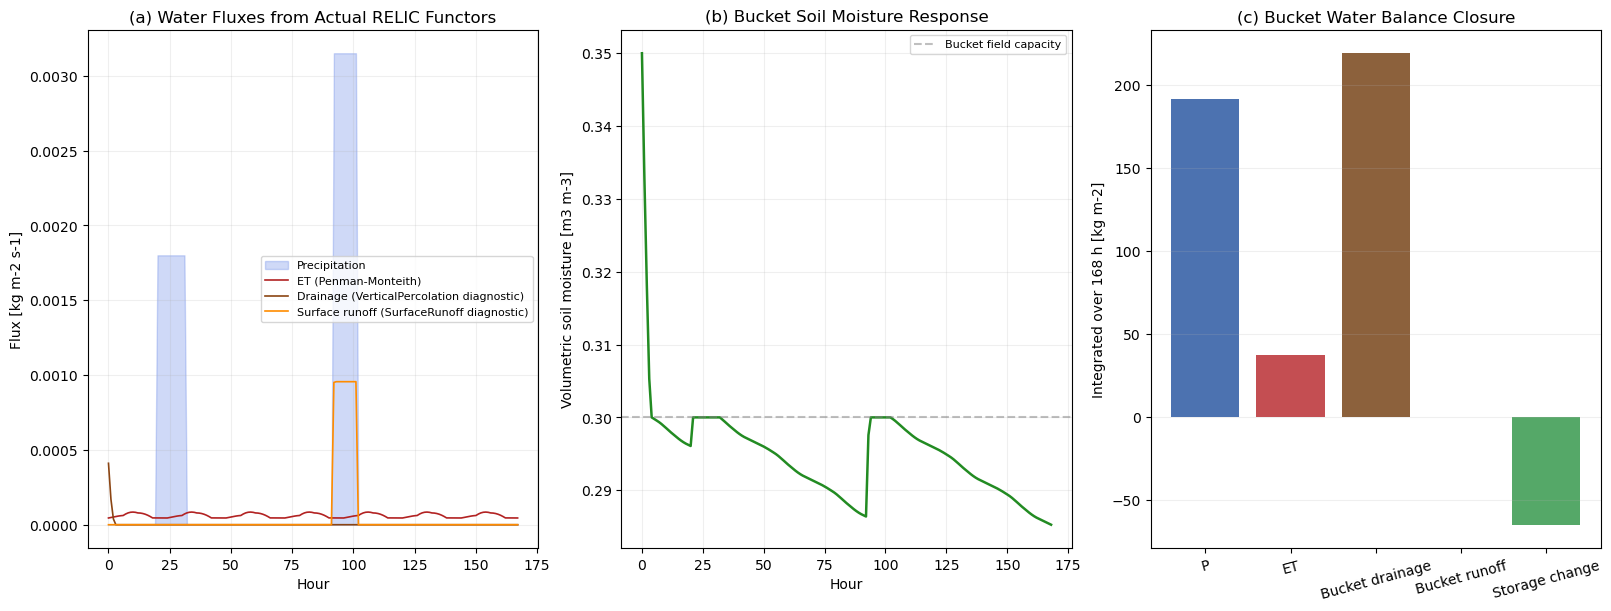

[OK] Dashboard checked: runoff_max=9.555557e-04, drainage_max=4.104923e-04, soil_moisture_range=(0.285, 0.350)
[OK] Bucket budget [kg m-2]: P=191.16, ET=37.05, Bucket drainage=218.85, Bucket runoff=0.00, Storage change=-64.74, residual=-4.88e-04


In [9]:
# === Bucket Water Balance and Flux Visualization ===
# References:
# - Monteith (1965); Allen et al. (1998) FAO-56 Penman-Monteith evapotranspiration.
# - Manabe (1969) bucket soil moisture balance.
# - SCS (1972), Horton (1933), Dunne and Black (1970) surface runoff partition.
# - van Genuchten (1980); Mualem (1976) conductivity used by the percolation closure.
# - RELIC implementations: penman_monteith.py, bucket.py, runoff/surface.py, transport/vertical_percolation.py.
# Mathematical expression:
# - ET(t) = PenmanMonteithET.forward(state_atmosphere).evapotranspiration_flux
# - theta(t + dt), D_b, Q_b = BucketSoilMoisture.forward(theta, P, ET, dt)
# - Bucket budget over the run: sum(P - ET_act - D_b - Q_b) * dt = rho_w * Z * (theta_end - theta_start)
# - Side diagnostics on the updated bucket state:
#   Q_surface = SurfaceRunoff.forward(theta, P).surface_runoff_flux
#   q_drain = VerticalPercolationTransport.forward(theta, T).drainage_flux
# Parameter meanings:
# - theta: volumetric soil water content; P: precipitation; ET: Penman-Monteith demand; ET_act: water-limited ET.
# - D_b, Q_b: drainage and saturation-excess runoff applied by the bucket; rho_w: water density; Z: bucket depth.
# - vapor_pressure_deficit, surface_resistance, aerodynamic_resistance: Penman-Monteith inputs.
# Units:
# - theta [m3 m-3]; water fluxes [kg m-2 s-1]; integrated terms [kg m-2]; VPD [Pa]; resistances [s m-1]; dt [s].
# Domain/constraints:
# - PenmanMonteithET uses relative_humidity when present, otherwise vapor_pressure_deficit; only VPD is passed.
# - The side-diagnostic fluxes are not fed back into the bucket state.
# Sign convention:
# - P enters the soil column; ET, drainage and runoff are positive exports.

import torch
import matplotlib.pyplot as plt
from IPython.display import display

from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.transport.vertical_percolation import VerticalPercolationTransport
from relic.scientific.hydrosphere.runoff.surface import SurfaceRunoff

bucket_functor = BucketSoilMoisture(name="tutorial_bucket_dashboard_real")
# canopy_resistance_source must be declared; "state" reads surface_resistance [s m-1] from the state.
penman_monteith_functor = PenmanMonteithET(
    name="tutorial_pm_dashboard_real",
    config={"canopy_resistance_source": "state"},
)
vertical_percolation_functor = VerticalPercolationTransport(name="tutorial_vp_dashboard_real")
surface_runoff_functor = SurfaceRunoff(name="tutorial_surface_dashboard_real")

n_hours = 168
dt_hour = 3600.0
hours = torch.arange(n_hours, dtype=torch.float32)
precipitation_flux_series = torch.zeros(n_hours, dtype=torch.float32)
precipitation_flux_series[20:32] = 0.0018
precipitation_flux_series[92:102] = 0.00315
net_radiation_series = 150.0 + 120.0 * torch.clamp(torch.sin(2.0 * torch.pi * (hours % 24.0) / 24.0), min=0.0)
air_temperature_series = 289.15 + 6.0 * torch.sin(2.0 * torch.pi * (hours - 6.0) / 24.0)
# Diurnal vapor pressure deficit between 0.8 and 2.0 kPa, converted to Pa for PenmanMonteithET.
vpd_series = 1000.0 * (0.8 + 1.2 * torch.clamp(torch.sin(2.0 * torch.pi * (hours - 6.0) / 24.0), min=0.0))

soil_moisture = torch.tensor(0.35, dtype=torch.float32)
soil_moisture_history = [soil_moisture.detach().clone()]
et_history = []
bucket_et_history = []
bucket_drainage_history = []
bucket_runoff_history = []
drainage_history = []
runoff_history = []
precipitation_history = []

for idx in range(n_hours):
    et_updates = penman_monteith_functor.forward(
        {
            "net_radiation": net_radiation_series[idx],
            "air_temperature": air_temperature_series[idx],
            "wind_speed": torch.tensor(2.0, dtype=torch.float32),
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
            "vapor_pressure_deficit": vpd_series[idx],
            "surface_resistance": torch.tensor(100.0, dtype=torch.float32),
            "aerodynamic_resistance": torch.tensor(50.0, dtype=torch.float32),
        },
        time=float(idx) * dt_hour,
        dt=dt_hour,
    )
    evapotranspiration_flux = unwrap_update(et_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32)

    bucket_updates = bucket_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux_series[idx],
            "evapotranspiration_flux": evapotranspiration_flux,
            "air_temperature": air_temperature_series[idx],
        },
        time=float(idx) * dt_hour,
        dt=dt_hour,
    )
    soil_moisture = unwrap_update(bucket_updates["soil_moisture"]).detach().to(dtype=torch.float32)
    bucket_drainage_history.append(unwrap_update(bucket_updates["drainage_flux"]).detach().to(dtype=torch.float32))
    bucket_runoff_history.append(unwrap_update(bucket_updates["surface_runoff_flux"]).detach().to(dtype=torch.float32))
    bucket_et_history.append(
        bucket_updates["diagnostics.soil_moisture_bucket"]["adjusted_evapotranspiration"].detach().to(dtype=torch.float32)
    )

    surface_updates = surface_runoff_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux_series[idx],
        },
        time=float(idx) * dt_hour,
        dt=dt_hour,
    )
    surface_runoff_flux = unwrap_update(surface_updates["surface_runoff_flux"]).detach().to(dtype=torch.float32)

    percolation_updates = vertical_percolation_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "soil_temperature": air_temperature_series[idx],
        },
        time=float(idx) * dt_hour,
        dt=dt_hour,
    )
    percolation_flux = unwrap_update(percolation_updates["drainage_flux"]).detach().to(dtype=torch.float32)

    soil_moisture_history.append(soil_moisture.detach().clone())
    et_history.append(evapotranspiration_flux.detach().clone())
    drainage_history.append(percolation_flux.detach().clone())
    runoff_history.append(surface_runoff_flux.detach().clone())
    precipitation_history.append(precipitation_flux_series[idx].detach().clone())

soil_moisture_history = torch.stack(soil_moisture_history)
et_history = torch.stack(et_history)
bucket_et_history = torch.stack(bucket_et_history)
bucket_drainage_history = torch.stack(bucket_drainage_history)
bucket_runoff_history = torch.stack(bucket_runoff_history)
drainage_history = torch.stack(drainage_history)
runoff_history = torch.stack(runoff_history)
precipitation_history = torch.stack(precipitation_history)

# Integrated bucket budget [kg m-2]; storage change = rho_w * Z * (theta_end - theta_start).
bucket_depth = to_float(bucket_functor.soil_depth)
bucket_water_density = to_float(bucket_functor.water_density)
bucket_field_capacity = to_float(bucket_functor.field_capacity)
storage_change = (soil_moisture_history[-1] - soil_moisture_history[0]) * bucket_depth * bucket_water_density
integrated_components = torch.stack([
    torch.sum(precipitation_history * dt_hour),
    torch.sum(bucket_et_history * dt_hour),
    torch.sum(bucket_drainage_history * dt_hour),
    torch.sum(bucket_runoff_history * dt_hour),
    storage_change,
])
integrated_labels = ["P", "ET", "Bucket drainage", "Bucket runoff", "Storage change"]
budget_residual = float(
    integrated_components[0] - integrated_components[1] - integrated_components[2]
    - integrated_components[3] - integrated_components[4]
)
assert abs(budget_residual) <= 1.0e-3 * float(integrated_components[0])

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

axes[0].fill_between(hours.tolist(), [0.0] * n_hours, precipitation_history.tolist(), color="royalblue", alpha=0.25, label="Precipitation")
axes[0].plot(hours.tolist(), et_history.tolist(), color="firebrick", lw=1.2, label="ET (Penman-Monteith)")
axes[0].plot(hours.tolist(), drainage_history.tolist(), color="saddlebrown", lw=1.2, label="Drainage (VerticalPercolation diagnostic)")
axes[0].plot(hours.tolist(), runoff_history.tolist(), color="darkorange", lw=1.2, label="Surface runoff (SurfaceRunoff diagnostic)")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Flux [kg m-2 s-1]")
axes[0].set_title("(a) Water Fluxes from Actual RELIC Functors")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.2)

axes[1].plot(torch.arange(n_hours + 1, dtype=torch.float32).tolist(), soil_moisture_history.tolist(), color="forestgreen", lw=1.8)
axes[1].axhline(bucket_field_capacity, color="gray", ls="--", alpha=0.5, label="Bucket field capacity")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Volumetric soil moisture [m3 m-3]")
axes[1].set_title("(b) Bucket Soil Moisture Response")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.2)

axes[2].bar(integrated_labels, integrated_components.tolist(), color=["#4C72B0", "#C44E52", "#8C613C", "#DD8452", "#55A868"])
axes[2].set_ylabel("Integrated over 168 h [kg m-2]")
axes[2].set_title("(c) Bucket Water Balance Closure")
axes[2].tick_params(axis="x", rotation=15)
axes[2].grid(True, axis="y", alpha=0.2)

display(plt.gcf())
plt.close(plt.gcf())
print(
    f"[OK] Dashboard checked: runoff_max={float(torch.max(runoff_history)):.6e}, "
    f"drainage_max={float(torch.max(drainage_history)):.6e}, "
    f"soil_moisture_range=({float(torch.min(soil_moisture_history)):.3f}, {float(torch.max(soil_moisture_history)):.3f})"
)
print(
    "[OK] Bucket budget [kg m-2]: "
    + ", ".join(f"{label}={float(value):.2f}" for label, value in zip(integrated_labels, integrated_components))
    + f", residual={budget_residual:.2e}"
)

---
## Advanced Hydrology Theory

> **Reference:** theory pages `docs/source/theory/hydrosphere_*.md`
>
> The following sections run `SnowPack` and `SnowAlbedo`, `PenmanMonteithET` and `PriestleyTaylorET`,
> `VerticalPercolationTransport` with `SubsurfaceRunoff`, and `SurfaceRunoff` with `BucketSoilMoisture`.
> `RichardsSoilMoisture`, `CapillaryRiseTransport`, `GroundwaterDynamics`, `SurfacePondingFunctor` and the
> pedosphere solute transport Functor `SoluteAdvectionDiffusion1D` have theory pages and are described by
> equations below, but they are not executed in this notebook.


### H1. Snowpack & Snow Albedo

> **Ref:** `hydrosphere_snowpack.md`, `hydrosphere_snow_albedo.md`

**Snow mass balance** (`SnowPack`):

$$\frac{dSWE}{dt} = P_s - M - E_s$$

where SWE is the snow water equivalent [mm], $P_s$ is snowfall, $M$ is melt and $E_s$ is sublimation (the `sublimation_flux` input, zero in this demo). All precipitation falls as snow when $T_a \le$ 273.15 K and as rain otherwise; rain bypasses the pack. Melt and then sublimation are limited by the SWE available at the start of the step. `SnowPack` has no blowing-snow term.

**Degree-day melt:**

$$M = \frac{a_m \max(0,\; T_a - T_m)}{86400}$$

with $a_m$ = 5 mm K$^{-1}$ day$^{-1}$ (`hydrosphere.snow.degree_day_factor`) and $T_m$ = 273.15 K. Snow depth is $SWE_m\,\rho_w/\rho_{snow}$, where UnitConverter converts updated SWE from mm to m; $\rho_{snow}$ = 250 kg m$^{-3}$. SnowPack emits explicit REPLACE UpdateItems in SCM units.

**Snow albedo** (`SnowAlbedo`): the default scheme is BATS (`hydrosphere.snow.albedo_scheme = bats`). The nondimensional snow age $\tau_s$ (state `snow_nondimensional_age`) grows as $\tau_s \leftarrow \tau_s + \Delta t\, k(T)\,(r_1 + r_2 + r_3)$, where $r_1$, $r_2$ and $r_3$ represent grain growth, melt-freeze and dirt effects, and lowers the visible and near-infrared albedo through $F_{age} = \tau_s/(1+\tau_s)$. Fresh snowfall above a threshold resets $\tau_s$ to zero, and a bare-ground albedo applies when the snow depth is below the minimum. The alternative `age_based` scheme uses the age $t$ in days (state `snow_surface_age`):

$$\alpha_s = \alpha_{old} + (\alpha_{fresh} - \alpha_{old})\, e^{-t f_T/\tau_a}$$

with $\alpha_{fresh}$ = 0.85, $\alpha_{old}$ = 0.5, $\tau_a$ = 5 days and a warm-temperature aging factor $f_T$. `SnowAlbedo` reads and writes only the age state of the active scheme; `SnowAlbedo.age_state_key` names it.

The stored output shows a peak SWE of 83.81 mm (snow depth 0.335 m), a maximum daily melt of 10.21 mm day$^{-1}$, and surface albedo between 0.300 (the bare-ground value used when no snow is present) and 0.806.


SnowAlbedo scheme=bats, age state=snow_nondimensional_age


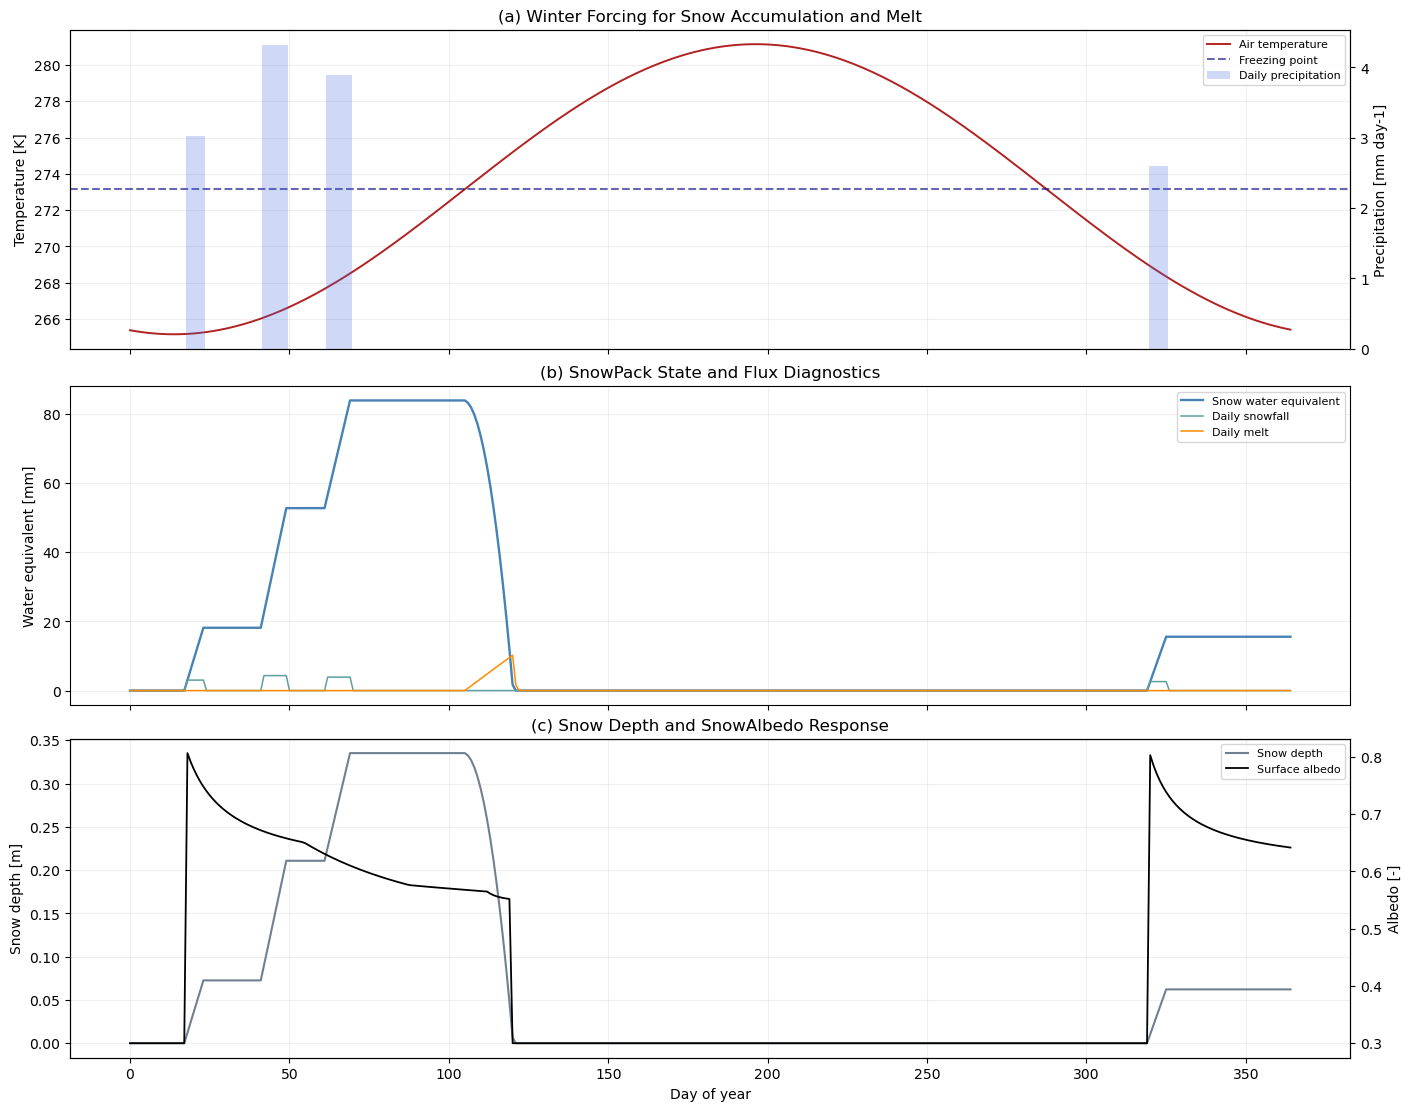

[OK] Snow diagnostics checked: SWE_max=83.81 mm, snow_depth_max=0.335 m, daily_melt_max=10.21 mm day-1, albedo_range=(0.300, 0.806)


In [10]:
# === Snowpack & Snow Albedo via RELIC Modules ===
# References:
# - Anderson (1976) snow accumulation and ablation; Hock (2003) temperature-index melt.
# - Dickinson et al. (1993) BATS snow albedo; Warren and Wiscombe (1980) snow albedo aging.
# - RELIC implementations: relic/scientific/hydrosphere/snow/snowpack.py and albedo.py.
# Mathematical expression:
# - snow_melt_flux = min(DDF * max(T_air - T_melt, 0) / 86400, SWE / dt)
# - SWE(t + dt) = max(SWE(t) + (snowfall - snow_melt_flux - sublimation_flux) * dt, 0)
# - SWE_m = UnitConverter.convert(SWE_mm, "snow_water_equivalent", "mm", "m")
# - snow_depth = SWE_m * rho_w / rho_snow; outputs are REPLACE items in SCM units.
# - surface_albedo, age(t + dt) = SnowAlbedo.forward(snowfall, snow_surface_temperature, air_temperature,
#   solar_zenith_angle, snow_depth, age(t)); age is the scheme-owned state named by age_state_key
# Parameter meanings:
# - precipitation_flux: total precipitation; snowfall and rain_flux: its snow and rain parts.
# - snow_water_equivalent (SWE); DDF: degree-day factor; T_melt: melt threshold; rho_snow: snow density.
# - surface_albedo: broadband surface albedo; age: BATS nondimensional age or age-based age in days.
# Units:
# - fluxes [kg m-2 s-1] (1 kg m-2 equals 1 mm of liquid water); SWE [mm]; snow_depth [m]; T [K];
#   DDF [mm K-1 day-1]; rho [kg m-3]; solar_zenith_angle [rad]; albedo [1]; dt [s].
# Domain/constraints:
# - dt > 0; melt and sublimation are limited by the available SWE; albedo is clipped to the YAML bounds.
# Sign convention:
# - Snowfall adds to SWE; melt and sublimation remove it; rain bypasses the pack.

import torch
import matplotlib.pyplot as plt
from IPython.display import display

from relic.scientific.hydrosphere.snow.snowpack import SnowPack
from relic.scientific.hydrosphere.snow.albedo import SnowAlbedo

snow_functor = SnowPack(name="tutorial_snowpack_real")
albedo_functor = SnowAlbedo(name="tutorial_snow_albedo_real")
# The active albedo scheme owns one age state: snow_nondimensional_age (bats) or snow_surface_age (age_based).
snow_age_key = albedo_functor.age_state_key
print(f"SnowAlbedo scheme={albedo_functor.albedo_scheme}, age state={snow_age_key}")

n_days = 365
dt_day = 86400.0
days = torch.arange(n_days, dtype=torch.float32)

air_temperature_series = 273.15 + 8.0 * torch.sin(2.0 * torch.pi * (days - 105.0) / 365.0)
precipitation_flux_series = torch.zeros(n_days, dtype=torch.float32)
precipitation_flux_series[18:24] = 0.000035
precipitation_flux_series[42:50] = 0.000050
precipitation_flux_series[62:70] = 0.000045
precipitation_flux_series[320:326] = 0.000030
solar_zenith_series = torch.clamp(1.1 - 0.55 * torch.sin(2.0 * torch.pi * (days - 82.0) / 365.0), min=0.18, max=1.35)

snow_water_equivalent = torch.tensor(0.0, dtype=torch.float32)
snow_age = torch.tensor(0.0, dtype=torch.float32)
sublimation_flux = torch.tensor(0.0, dtype=torch.float32)

swe_history = []
melt_history = []
snowfall_history = []
rain_history = []
albedo_history = []
snow_depth_history = []

for idx in range(n_days):
    current_temp = air_temperature_series[idx]
    current_precip = precipitation_flux_series[idx]

    snow_updates = snow_functor.forward(
        {
            "precipitation_flux": current_precip,
            "air_temperature": current_temp,
            "snow_water_equivalent": snow_water_equivalent,
            "sublimation_flux": sublimation_flux,
        },
        time=float(idx) * dt_day,
        dt=dt_day,
    )
    snow_water_equivalent = unwrap_update(snow_updates["snow_water_equivalent"]).detach().to(dtype=torch.float32)
    snow_depth = unwrap_update(snow_updates["snow_depth"]).detach().to(dtype=torch.float32)
    snow_melt_flux = unwrap_update(snow_updates["snow_melt_flux"]).detach().to(dtype=torch.float32)
    snowfall_flux = unwrap_update(snow_updates["snowfall"]).detach().to(dtype=torch.float32)
    rain_flux = unwrap_update(snow_updates["rain_flux"]).detach().to(dtype=torch.float32)

    albedo_updates = albedo_functor.forward(
        {
            "snowfall": snowfall_flux,
            "snow_surface_temperature": current_temp - 1.0,
            "air_temperature": current_temp,
            "solar_zenith_angle": solar_zenith_series[idx],
            "snow_depth": snow_depth,
            snow_age_key: snow_age,
        },
        time=float(idx) * dt_day,
        dt=dt_day,
    )
    surface_albedo = unwrap_update(albedo_updates["surface_albedo"]).detach().to(dtype=torch.float32)
    snow_age = unwrap_update(albedo_updates[snow_age_key]).detach().to(dtype=torch.float32)

    swe_history.append(snow_water_equivalent)
    melt_history.append(snow_melt_flux)
    snowfall_history.append(snowfall_flux)
    rain_history.append(rain_flux)
    albedo_history.append(surface_albedo)
    snow_depth_history.append(snow_depth)

swe_history = torch.stack(swe_history)
melt_history = torch.stack(melt_history)
snowfall_history = torch.stack(snowfall_history)
rain_history = torch.stack(rain_history)
albedo_history = torch.stack(albedo_history)
snow_depth_history = torch.stack(snow_depth_history)

daily_precipitation = precipitation_flux_series * dt_day
daily_snowfall = snowfall_history * dt_day
daily_melt = melt_history * dt_day

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, constrained_layout=True)

forcing_ax = axes[0]
forcing_precip_ax = forcing_ax.twinx()
forcing_ax.plot(days.tolist(), air_temperature_series.tolist(), color="firebrick", lw=1.4, label="Air temperature")
forcing_ax.axhline(273.15, color="navy", ls="--", alpha=0.6, label="Freezing point")
forcing_precip_ax.bar(days.tolist(), daily_precipitation.tolist(), color="royalblue", alpha=0.25, width=1.0, label="Daily precipitation")
forcing_ax.set_ylabel("Temperature [K]")
forcing_precip_ax.set_ylabel("Precipitation [mm day-1]")
forcing_ax.set_title("(a) Winter Forcing for Snow Accumulation and Melt")
forcing_ax.grid(True, alpha=0.2)
forcing_handles, forcing_labels = forcing_ax.get_legend_handles_labels()
precip_handles, precip_labels = forcing_precip_ax.get_legend_handles_labels()
forcing_ax.legend(forcing_handles + precip_handles, forcing_labels + precip_labels, fontsize=8, loc="upper right")

storage_ax = axes[1]
storage_ax.plot(days.tolist(), swe_history.tolist(), color="steelblue", lw=1.7, label="Snow water equivalent")
storage_ax.plot(days.tolist(), daily_snowfall.tolist(), color="cadetblue", lw=1.1, label="Daily snowfall")
storage_ax.plot(days.tolist(), daily_melt.tolist(), color="darkorange", lw=1.1, label="Daily melt")
storage_ax.set_ylabel("Water equivalent [mm]")
storage_ax.set_title("(b) SnowPack State and Flux Diagnostics")
storage_ax.grid(True, alpha=0.2)
storage_ax.legend(fontsize=8, loc="upper right")

depth_ax = axes[2]
albedo_ax = depth_ax.twinx()
depth_ax.plot(days.tolist(), snow_depth_history.tolist(), color="slategray", lw=1.5, label="Snow depth")
albedo_ax.plot(days.tolist(), albedo_history.tolist(), color="black", lw=1.3, label="Surface albedo")
depth_ax.set_ylabel("Snow depth [m]")
albedo_ax.set_ylabel("Albedo [-]")
depth_ax.set_xlabel("Day of year")
depth_ax.set_title("(c) Snow Depth and SnowAlbedo Response")
depth_ax.grid(True, alpha=0.2)
depth_handles, depth_labels = depth_ax.get_legend_handles_labels()
albedo_handles, albedo_labels = albedo_ax.get_legend_handles_labels()
depth_ax.legend(depth_handles + albedo_handles, depth_labels + albedo_labels, fontsize=8, loc="upper right")

display(plt.gcf())
plt.close(plt.gcf())
print(
    f"[OK] Snow diagnostics checked: SWE_max={float(torch.max(swe_history)):.2f} mm, "
    f"snow_depth_max={float(torch.max(snow_depth_history)):.3f} m, "
    f"daily_melt_max={float(torch.max(daily_melt)):.2f} mm day-1, "
    f"albedo_range=({float(torch.min(albedo_history)):.3f}, {float(torch.max(albedo_history)):.3f})"
)

### H2. Evapotranspiration Methods

> **Ref:** `hydrosphere_penman_monteith.md`, `hydrosphere_priestley_taylor.md`

**Penman-Monteith equation** (`PenmanMonteithET`):

$$\lambda E = \frac{\Delta (R_n - G) + \rho_a c_p \frac{(e^* - e_a)}{r_a}}{\Delta + \gamma (1 + r_s / r_a)}$$

where $\Delta$ is the slope of the saturation vapor pressure curve, $G = 0.1R_n$ for $R_n>0$ and $G=0.5R_n$ otherwise (`hydrosphere.physical.soil_heat_flux_ratio_daytime` and `soil_heat_flux_ratio_nighttime`), $r_a$ is the aerodynamic resistance (taken from the state when present, otherwise computed from wind speed), $r_s$ is the surface (canopy) resistance and $\gamma$ is the psychrometric constant. The vapor pressure deficit $e^* - e_a$ comes from `relative_humidity` when present, otherwise from `vapor_pressure_deficit` [Pa].

`PenmanMonteithET` requires `config["canopy_resistance_source"]`: `"state"` reads `surface_resistance` [s m$^{-1}$] from the state (or $1/g_c$ from `canopy_conductance`), and `"fao56_reference_surface"` uses the FAO-56 reference grass value $r_s$ = 70 s m$^{-1}$ (`hydrosphere.physical.reference_surface_resistance`). The cells use `"state"` because they vary $r_s$. The hourly FAO-56 relation rejects actual `dt > 3600` s. Both physical and reference denominators must be finite and positive; air density is computed from temperature, pressure and actual vapor pressure.

**Priestley-Taylor equation** (`PriestleyTaylorET`, equilibrium ET scaled by $\alpha_{\text{PT}}$):

$$\lambda E = \alpha_{\text{PT}} \frac{\Delta}{\Delta + \gamma} (R_n - G)$$

with $\alpha_{\text{PT}}$ = 1.26 (`hydrosphere.evapotranspiration.alpha_pt`) and $G = 0.1 R_n$ (`hydrosphere.evapotranspiration.soil_heat_fraction`). With `hydrosphere.evapotranspiration.enable_dynamic_alpha = false`, `PriestleyTaylorET` reads only `net_radiation`, `air_temperature` and `atmospheric_pressure`; it computes $G$ and the available energy $R_n - G$ itself and reports the latter in its diagnostics.

The cell prints freshly evaluated PM and PT responses. The VPD sweep uses
0.3--3.0 kPa at 298.15 K; the temperature sweep starts at 288.15 K so its
fixed 1500 Pa VPD does not imply negative actual vapor pressure.

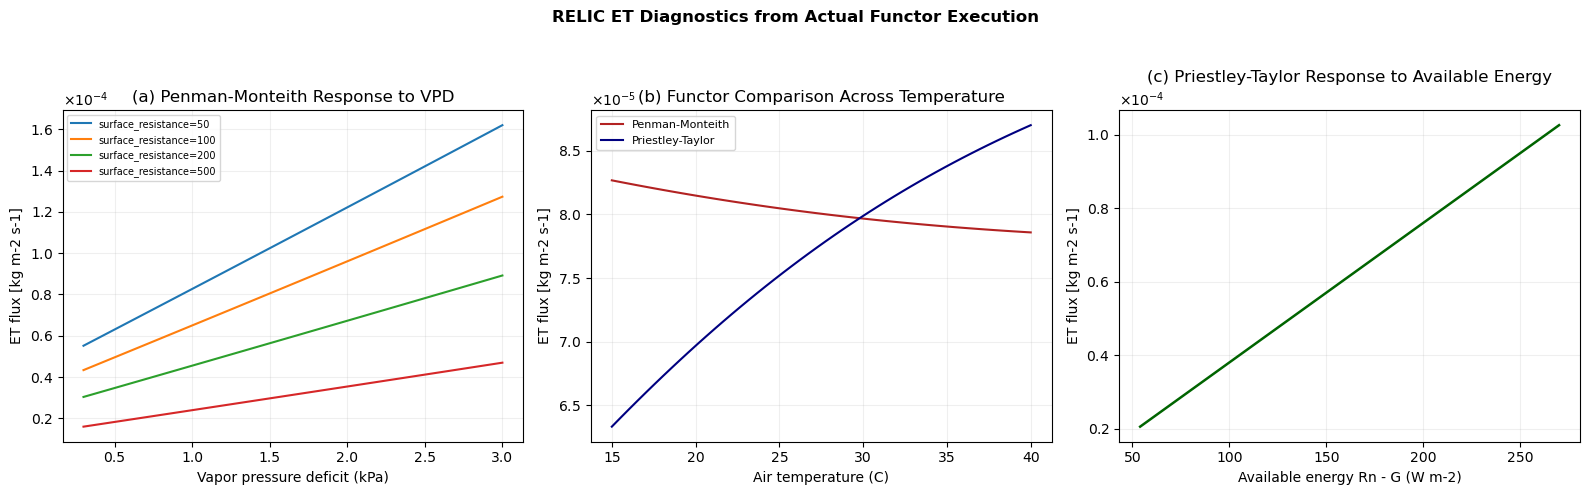

[OK] Panel (a) uses explicit VPD forcing without relative_humidity override.
surface_resistance= 50 s m-1 | actual_vpd_kPa=(0.30, 3.00) | et_flux=(5.518e-05, 1.620e-04)
surface_resistance=100 s m-1 | actual_vpd_kPa=(0.30, 3.00) | et_flux=(4.338e-05, 1.273e-04)
surface_resistance=200 s m-1 | actual_vpd_kPa=(0.30, 3.00) | et_flux=(3.038e-05, 8.919e-05)
surface_resistance=500 s m-1 | actual_vpd_kPa=(0.30, 3.00) | et_flux=(1.600e-05, 4.698e-05)
[OK] Priestley-Taylor available energy (54.0, 270.0) W m-2 -> ET (2.051e-05, 1.025e-04) kg m-2 s-1


In [11]:
# === ET Methods via RELIC Modules ===
# References:
# - Monteith (1965) evaporation and environment; Allen et al. (1998) FAO-56 crop evapotranspiration.
# - Priestley and Taylor (1972) assessment of surface heat flux.
# - RELIC implementations: penman_monteith.py and priestley_taylor.py.
# Mathematical expression:
# - ET_PM = [Delta*(Rn-G) + rho_a*c_p*VPD/r_a] / [lambda*(Delta+gamma*(1+r_s/r_a))]
# - PM G = c_day*Rn for Rn>0, otherwise c_night*Rn; YAML values are 0.1 and 0.5.
# - rho_a = compute_moist_air_density(T, p, e_a); both denominator checks remain active.
# - ET_PT = alpha_PT * Delta / (Delta + gamma) * (Rn - G) / lambda, G = 0.1 Rn
# - VPD = e_s(T) - e_a, passed directly as vapor_pressure_deficit
# Parameter meanings:
# - Rn: net_radiation; G: soil heat flux; VPD: vapor_pressure_deficit; r_s: surface_resistance;
#   r_a: aerodynamic_resistance; alpha_PT: Priestley-Taylor coefficient (1.26 in YAML).
# - Delta: slope of the saturation vapor pressure curve; gamma: psychrometric constant; lambda: latent heat.
# - diagnostic_dt: time step passed to forward.
# Units:
# - ET [kg m-2 s-1]; Rn, G [W m-2]; VPD [Pa]; r_s, r_a [s m-1]; T [K]; Delta, gamma [Pa K-1]; lambda [J kg-1]; dt [s].
# Domain/constraints:
# - PM needs canopy_resistance_source ("state" here), positive r_s/r_a and dt<=3600 s.
# - Heat ratios: hydrosphere.physical.soil_heat_flux_ratio_daytime/_nighttime.
# - Selected forcing keeps e_a = e_s(T)-VPD non-negative.
# - PriestleyTaylorET reads only net_radiation, air_temperature and atmospheric_pressure; ET is clamped at zero.
# Sign convention:
# - Positive ET is water leaving the surface; positive Rn supplies energy to the surface.

import torch
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.evapotranspiration.priestley_taylor import PriestleyTaylorET

# canopy_resistance_source="state": surface_resistance is read from the state on every call.
penman_monteith = PenmanMonteithET(
    name="tutorial_penman_monteith_real",
    config={"canopy_resistance_source": "state"},
)
priestley_taylor = PriestleyTaylorET(name="tutorial_priestley_taylor_real")

diagnostic_dt = 1800.0
vpd_values_kpa = torch.linspace(0.3, 3.0, 40, dtype=torch.float32)
vpd_values_pa = vpd_values_kpa * 1000.0
surface_resistance_values = [50.0, 100.0, 200.0, 500.0]
temperature_values = torch.linspace(288.15, 313.15, 50, dtype=torch.float32)
net_radiation_values = torch.linspace(60.0, 300.0, 40, dtype=torch.float32)

pm_vpd_curves = {}
pm_vpd_diagnostics = {}
for resistance in surface_resistance_values:
    fluxes = []
    actual_vpd_series = []
    for vpd_pa in vpd_values_pa:
        pm_updates = penman_monteith.forward(
            {
                "net_radiation": torch.tensor(220.0, dtype=torch.float32),
                "air_temperature": torch.tensor(298.15, dtype=torch.float32),
                "wind_speed": torch.tensor(2.5, dtype=torch.float32),
                "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
                "vapor_pressure_deficit": vpd_pa,
                "surface_resistance": torch.tensor(resistance, dtype=torch.float32),
                "aerodynamic_resistance": torch.tensor(35.0, dtype=torch.float32),
            },
            time=0.0,
            dt=diagnostic_dt,
        )
        fluxes.append(unwrap_update(pm_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32))
        actual_vpd_series.append(
            unwrap_update(pm_updates["diagnostics.vapor_pressure_deficit"]).detach().to(dtype=torch.float32)
        )
    pm_vpd_curves[resistance] = torch.stack(fluxes)
    pm_vpd_diagnostics[resistance] = torch.stack(actual_vpd_series)

pm_temperature_fluxes = []
pt_temperature_fluxes = []
for temperature in temperature_values:
    pm_updates = penman_monteith.forward(
        {
            "net_radiation": torch.tensor(220.0, dtype=torch.float32),
            "air_temperature": temperature,
            "wind_speed": torch.tensor(2.5, dtype=torch.float32),
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
            "vapor_pressure_deficit": torch.tensor(1500.0, dtype=torch.float32),
            "surface_resistance": torch.tensor(100.0, dtype=torch.float32),
            "aerodynamic_resistance": torch.tensor(35.0, dtype=torch.float32),
        },
        time=0.0,
        dt=diagnostic_dt,
    )
    pt_updates = priestley_taylor.forward(
        {
            "net_radiation": torch.tensor(220.0, dtype=torch.float32),
            "air_temperature": temperature,
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
        },
        time=0.0,
        dt=diagnostic_dt,
    )
    pm_temperature_fluxes.append(unwrap_update(pm_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32))
    pt_temperature_fluxes.append(unwrap_update(pt_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32))

pm_temperature_fluxes = torch.stack(pm_temperature_fluxes)
pt_temperature_fluxes = torch.stack(pt_temperature_fluxes)

# Priestley-Taylor computes G = 0.1 Rn itself; the x axis uses its reported available energy Rn - G.
pt_energy_fluxes = []
pt_available_energy = []
for net_radiation in net_radiation_values:
    pt_updates = priestley_taylor.forward(
        {
            "net_radiation": net_radiation,
            "air_temperature": torch.tensor(298.15, dtype=torch.float32),
            "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
        },
        time=0.0,
        dt=diagnostic_dt,
    )
    pt_energy_fluxes.append(unwrap_update(pt_updates["evapotranspiration_flux"]).detach().to(dtype=torch.float32))
    pt_available_energy.append(
        pt_updates["diagnostics.evapotranspiration"]["available_energy"].detach().to(dtype=torch.float32)
    )
pt_energy_fluxes = torch.stack(pt_energy_fluxes)
pt_available_energy = torch.stack(pt_available_energy)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for resistance in surface_resistance_values:
    axes[0].plot(vpd_values_kpa.tolist(), pm_vpd_curves[resistance].tolist(), lw=1.5, label=f"surface_resistance={int(resistance)}")
axes[0].set_xlabel("Vapor pressure deficit (kPa)")
axes[0].set_ylabel("ET flux [kg m-2 s-1]")
axes[0].set_title("(a) Penman-Monteith Response to VPD")
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.2)

axes[1].plot((temperature_values - 273.15).tolist(), pm_temperature_fluxes.tolist(), color="firebrick", lw=1.5, label="Penman-Monteith")
axes[1].plot((temperature_values - 273.15).tolist(), pt_temperature_fluxes.tolist(), color="navy", lw=1.5, label="Priestley-Taylor")
axes[1].set_xlabel("Air temperature (C)")
axes[1].set_ylabel("ET flux [kg m-2 s-1]")
axes[1].set_title("(b) Functor Comparison Across Temperature")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.2)

axes[2].plot(pt_available_energy.tolist(), pt_energy_fluxes.tolist(), color="darkgreen", lw=1.8)
axes[2].set_xlabel("Available energy Rn - G (W m-2)")
axes[2].set_ylabel("ET flux [kg m-2 s-1]")
axes[2].set_title("(c) Priestley-Taylor Response to Available Energy")
axes[2].grid(True, alpha=0.2)

# Clean up scientific notation on y-axes
import matplotlib.ticker as mticker
for ax_i in axes:
    ax_i.yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
    ax_i.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))
plt.suptitle("RELIC ET Diagnostics from Actual Functor Execution", fontweight="bold")
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.95])
display(plt.gcf())
plt.close(plt.gcf())

print("[OK] Panel (a) uses explicit VPD forcing without relative_humidity override.")
for resistance in surface_resistance_values:
    actual_vpd_kpa = (pm_vpd_diagnostics[resistance] / 1000.0).to(dtype=torch.float64)
    et_fluxes = pm_vpd_curves[resistance].to(dtype=torch.float64)
    print(
        f"surface_resistance={int(resistance):>3d} s m-1 | "
        f"actual_vpd_kPa=({actual_vpd_kpa[0].tolist():.2f}, {actual_vpd_kpa[-1].tolist():.2f}) | "
        f"et_flux=({et_fluxes[0].tolist():.3e}, {et_fluxes[-1].tolist():.3e})"
    )
print(
    f"[OK] Priestley-Taylor available energy ({float(pt_available_energy[0]):.1f}, {float(pt_available_energy[-1]):.1f}) W m-2 "
    f"-> ET ({float(pt_energy_fluxes[0]):.3e}, {float(pt_energy_fluxes[-1]):.3e}) kg m-2 s-1"
)

### H3. Vertical Percolation & Groundwater

> **Ref:** `hydrosphere_vertical_percolation.md`, `hydrosphere_groundwater_dynamics.md`,
> `hydrosphere_capillary_rise.md`, `hydrosphere_richards.md`

**Richards equation** (`RichardsSoilMoisture`, not run here; $z$ positive downward):

$$\frac{\partial \theta}{\partial t} = \frac{\partial}{\partial z}\left[K(\theta) \left(\frac{\partial h}{\partial z} - 1\right)\right] - S(\theta)$$

**Reduced-order gravity drainage** (`VerticalPercolationTransport`, run below). The Functor returns a drainage flux and does not advance soil moisture:

$$F_{drain} = \rho_w\, \Delta z\, \frac{\max(0, \theta - \theta_{fc})}{\tau_{drain}}\, \frac{K(\theta)}{K_s}, \qquad
K(\theta) = K_s S_e^{\,l}\left[1 - \left(1 - S_e^{1/m}\right)^m\right]^2$$

with the van Genuchten-Mualem conductivity, $S_e = (\theta - \theta_r)/(\theta_s - \theta_r)$ and $m = 1 - 1/n$. The YAML values are $\Delta z$ = 1.0 m (`hydrosphere.transport.soil_layer_thickness`), $\tau_{drain}$ = 3600 s, $\theta_{fc}$ = 0.30, $\theta_r$ = 0.045, $\theta_s$ = 0.43, $n$ = 1.89 and $l$ = 0.5; $K$ also carries a viscosity temperature correction.

**Capillary rise** (`CapillaryRiseTransport`, not run here; Gardner 1958):

$$q_{cap} = \min\left(\frac{B\,a}{Z_{wt}^{\,b}},\; K_s\right), \qquad B = 1 + \frac{1.5}{b - 1}$$

where $Z_{wt}$ is the water-table depth and $a$, $b$ are the Gardner coefficients derived from the soil hydraulic parameters.

**Groundwater storage** (`GroundwaterDynamics`, not run here):

$$\frac{dS}{dt} = q_{drain} + q_{lat} - q_{pump} - q_{cap} - q_{base}, \qquad
S_{profile}(z_{wt}) = 1000 \int_{z_{wt}}^{z_{bedrock}} n_0\, e^{-s/p}\, ds$$

where $S$ is groundwater storage [mm], the $q$ terms are depth rates [mm s$^{-1}$], and the water-table depth $z_{wt}$ follows from the storage through the porosity profile $n(z) = n_0 e^{-z/p}$.

The code cell below stacks four 1.0 m layers and uses the `VerticalPercolationTransport` flux of each layer as the inflow of the layer below. The layer storage update is done in the notebook with the same $\Delta z$ the Functor uses, in 300 s substeps. The daily-mean bottom drainage is the recharge of `SubsurfaceRunoff` (section H4 gives its equations).

The stored output shows every layer draining to the field capacity 0.300 by day 30, and the daily bottom drainage falling from 9.086e-4 kg m$^{-2}$ s$^{-1}$ on day 1 to 1.983e-7 kg m$^{-2}$ s$^{-1}$ on day 30. The groundwater store drops from 80 mm to 0 mm on day 1 and stays empty. On day 1 the initial 80 mm storage plus about 78.5 mm recharge exceeds the 100 mm capacity, and the overflow leaves through the same outlet (subsurface runoff 1.835e-3 kg m$^{-2}$ s$^{-1}$). The store stays empty because `hydrosphere.runoff.baseflow_recession_constant` is 0.01 s$^{-1}$, a 100 s time constant: $k\,\Delta t$ = 864 for a daily step, so the storage limit releases the whole store plus the day's recharge in every step, and the subsurface runoff equals the recharge from day 2 on. This time constant is far shorter than the day-scale baseflow recession described by the recession literature the parameter cites (Tallaksen 1995).


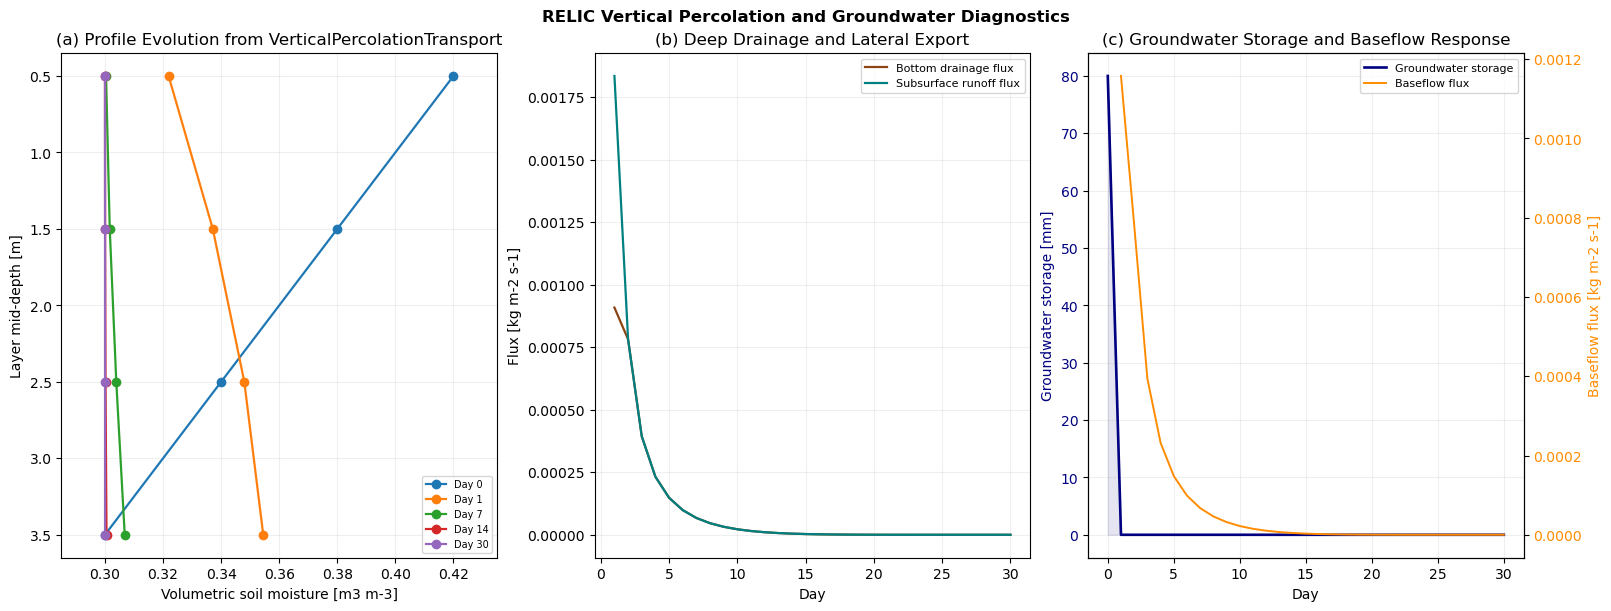

[OK] Layer theta day 0 -> day 30: 0.420->0.300, 0.380->0.300, 0.340->0.300, 0.300->0.300
[OK] Bottom drainage: day 1 = 9.086e-04, day 30 = 1.983e-07 kg m-2 s-1
[OK] Groundwater storage [mm]: day 0 = 80.00, day 1 = 0.00, day 30 = 0.00; subsurface runoff day 1 = 1.835e-03 kg m-2 s-1


In [12]:
# === Vertical Percolation via RELIC Module ===
# References:
# - van Genuchten (1980); Mualem (1976) unsaturated hydraulic conductivity.
# - Darcy (1856); Buckingham (1907) gravity drainage.
# - Brutsaert and Nieber (1977); Tallaksen (1995) baseflow recession.
# - RELIC implementations: relic/scientific/hydrosphere/transport/vertical_percolation.py,
#   relic/scientific/hydrosphere/runoff/subsurface.py.
# Mathematical expression:
# - q_i = VerticalPercolationTransport.forward(theta_i, T).drainage_flux
#       = rho_w * dz * max(theta_i - theta_fc, 0) / tau_drain * K(theta_i) / K_s
# - Notebook cascade (not a RELIC Functor): theta_i(t + dt) = theta_i(t) + (q_(i-1) - q_i) * dt / (rho_w * dz), q_0 = 0
# - SubsurfaceRunoff: S* = min(S + R * dt, S_max); V = min((k * S* + Q_i) * dt, S*); S(t + dt) = S* - V;
#   subsurface_runoff_flux Q = (V + overflow) / dt
# Parameter meanings:
# - theta_i: layer water content; theta_fc: field capacity; tau_drain: drainage time constant; K / K_s: relative conductivity.
# - dz: layer thickness, equal to the Functor's hydrosphere.transport.soil_layer_thickness.
# - R: daily-mean bottom drainage (recharge); S: groundwater storage; S_max: storage capacity;
#   k: hydrosphere.runoff.baseflow_recession_constant; Q_i: interflow; overflow = max(S + R * dt - S_max, 0).
# Units:
# - theta [m3 m-3]; q, R, Q [kg m-2 s-1]; dz [m]; tau_drain, dt [s]; rho_w [kg m-3]; S [mm]; k [s-1].
# Domain/constraints:
# - theta must stay within [theta_r, theta_s] (asserted); dt_substep = 300 s is short against tau_drain = 3600 s.
# - The initial groundwater storage (80 mm) is below the storage capacity (100 mm).
# Sign convention:
# - q and R are positive downward; subsurface runoff and baseflow are positive lateral exports.

import torch
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

from relic.scientific.hydrosphere.transport.vertical_percolation import VerticalPercolationTransport
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff

vertical_percolation = VerticalPercolationTransport(name="tutorial_vertical_percolation_real")
subsurface_runoff = SubsurfaceRunoff(name="tutorial_subsurface_runoff_real")

n_layers = 4
layer_thickness = float(vertical_percolation.soil_layer_thickness)  # m, the dz used inside the Functor
layer_depths = (torch.arange(n_layers, dtype=torch.float32) + 0.5) * layer_thickness  # layer mid-depths [m]
soil_moisture_profile = torch.tensor([0.42, 0.38, 0.34, 0.30], dtype=torch.float32)
groundwater_storage = torch.tensor(80.0, dtype=torch.float32)  # mm

dt_day = 86400.0
dt_substep = 300.0
n_days = 30
profile_history = [soil_moisture_profile.detach().clone()]
bottom_drainage_history = []
groundwater_storage_history = [groundwater_storage.detach().clone()]
subsurface_flux_history = []
baseflow_history = []

for day_idx in range(n_days):
    bottom_drainage_integral = torch.zeros((), dtype=torch.float32)
    for substep_in_day in range(int(dt_day // dt_substep)):
        percolation_updates = vertical_percolation.forward(
            {
                "soil_moisture": soil_moisture_profile,
                "soil_temperature": torch.full_like(soil_moisture_profile, 288.15),
            },
            time=float(day_idx) * dt_day + float(substep_in_day) * dt_substep,
            dt=dt_substep,
        )
        percolation_flux = unwrap_update(percolation_updates["drainage_flux"]).detach().to(dtype=torch.float32)
        incoming_flux = torch.cat([torch.zeros_like(percolation_flux[:1]), percolation_flux[:-1]])
        delta_theta = (incoming_flux - percolation_flux) * dt_substep / (vertical_percolation.water_density * layer_thickness)
        next_soil_moisture_profile = soil_moisture_profile + delta_theta
        assert torch.all(next_soil_moisture_profile >= vertical_percolation.theta_r)
        assert torch.all(next_soil_moisture_profile <= vertical_percolation.theta_s)
        soil_moisture_profile = next_soil_moisture_profile.detach().to(dtype=torch.float32)
        bottom_drainage_integral = bottom_drainage_integral + percolation_flux[-1] * dt_substep
    daily_bottom_drainage_flux = bottom_drainage_integral / dt_day

    subsurface_updates = subsurface_runoff.forward(
        {
            "soil_moisture": torch.mean(soil_moisture_profile),
            "groundwater_storage": groundwater_storage,
            "drainage_flux": daily_bottom_drainage_flux,
        },
        time=float(day_idx) * dt_day,
        dt=dt_day,
    )
    groundwater_storage = unwrap_update(subsurface_updates["groundwater_storage"]).detach().to(dtype=torch.float32)
    subsurface_flux = unwrap_update(subsurface_updates["subsurface_runoff_flux"]).detach().to(dtype=torch.float32)
    baseflow_flux = unwrap_update(subsurface_updates["diagnostics.subsurface_runoff.baseflow_flux"]).detach().to(dtype=torch.float32)

    profile_history.append(soil_moisture_profile.detach().clone())
    bottom_drainage_history.append(daily_bottom_drainage_flux.detach().clone())
    groundwater_storage_history.append(groundwater_storage.detach().clone())
    subsurface_flux_history.append(subsurface_flux.detach().clone())
    baseflow_history.append(baseflow_flux.detach().clone())

profile_history = torch.stack(profile_history)
bottom_drainage_history = torch.stack(bottom_drainage_history)
groundwater_storage_history = torch.stack(groundwater_storage_history)
subsurface_flux_history = torch.stack(subsurface_flux_history)
baseflow_history = torch.stack(baseflow_history)

day_axis = torch.arange(n_days + 1, dtype=torch.float32)
flux_day_axis = torch.arange(1, n_days + 1, dtype=torch.float32)
profile_x_min = float(torch.min(profile_history).item()) - 0.015
profile_x_max = float(torch.max(profile_history).item()) + 0.015

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

for snapshot in [0, 1, 7, 14, 30]:
    axes[0].plot(profile_history[snapshot].tolist(), layer_depths.tolist(), marker="o", lw=1.6, label=f"Day {snapshot}")
axes[0].invert_yaxis()
axes[0].set_xlim(profile_x_min, profile_x_max)
axes[0].set_xlabel("Volumetric soil moisture [m3 m-3]")
axes[0].set_ylabel("Layer mid-depth [m]")
axes[0].set_title("(a) Profile Evolution from VerticalPercolationTransport")
axes[0].legend(fontsize=7, loc="lower right")
axes[0].grid(True, alpha=0.2)

axes[1].plot(flux_day_axis.tolist(), bottom_drainage_history.tolist(), color="saddlebrown", lw=1.6, label="Bottom drainage flux")
axes[1].plot(flux_day_axis.tolist(), subsurface_flux_history.tolist(), color="teal", lw=1.6, label="Subsurface runoff flux")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Flux [kg m-2 s-1]")
axes[1].set_title("(b) Deep Drainage and Lateral Export")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].grid(True, alpha=0.2)

storage_ax = axes[2]
flux_ax = storage_ax.twinx()
storage_ax.fill_between(day_axis.tolist(), [0.0] * len(day_axis), groundwater_storage_history.tolist(), color="navy", alpha=0.10)
storage_ax.plot(day_axis.tolist(), groundwater_storage_history.tolist(), color="navy", lw=1.9, label="Groundwater storage")
flux_ax.plot(flux_day_axis.tolist(), baseflow_history.tolist(), color="darkorange", lw=1.4, label="Baseflow flux")
storage_ax.set_xlabel("Day")
storage_ax.set_ylabel("Groundwater storage [mm]", color="navy")
flux_ax.set_ylabel("Baseflow flux [kg m-2 s-1]", color="darkorange")
storage_ax.tick_params(axis="y", labelcolor="navy")
flux_ax.tick_params(axis="y", labelcolor="darkorange")
storage_ax.set_title("(c) Groundwater Storage and Baseflow Response")
storage_ax.grid(True, alpha=0.2)
storage_handles, storage_labels = storage_ax.get_legend_handles_labels()
flux_handles, flux_labels = flux_ax.get_legend_handles_labels()
storage_ax.legend(storage_handles + flux_handles, storage_labels + flux_labels, fontsize=8, loc="upper right")

plt.suptitle("RELIC Vertical Percolation and Groundwater Diagnostics", fontweight="bold")
display(plt.gcf())
plt.close(plt.gcf())
print(
    "[OK] Layer theta day 0 -> day 30: "
    + ", ".join(f"{float(a):.3f}->{float(b):.3f}" for a, b in zip(profile_history[0], profile_history[-1]))
)
print(
    f"[OK] Bottom drainage: day 1 = {float(bottom_drainage_history[0]):.3e}, "
    f"day 30 = {float(bottom_drainage_history[-1]):.3e} kg m-2 s-1"
)
print(
    f"[OK] Groundwater storage [mm]: day 0 = {float(groundwater_storage_history[0]):.2f}, "
    f"day 1 = {float(groundwater_storage_history[1]):.2f}, day 30 = {float(groundwater_storage_history[-1]):.2f}; "
    f"subsurface runoff day 1 = {float(subsurface_flux_history[0]):.3e} kg m-2 s-1"
)

### H4. Surface & Subsurface Runoff

> **Ref:** `hydrosphere_surface_runoff.md`, `hydrosphere_subsurface_runoff.md`, `pedosphere_transport.md`

**Surface runoff** (`SurfaceRunoff`, default `runoff_method = combined` with `runoff_combination_method = max`): the Functor evaluates three mechanisms from the top-layer moisture and keeps the largest, capped by precipitation:

$$Q_s = \min\left(P,\; \max(Q_{SCS}, Q_{H}, Q_{sat})\right), \qquad I = P - Q_s$$

- SCS curve number on the step depth: $Q_{SCS} = (P\Delta t - I_a)^2 / (P\Delta t - I_a + S)$ for $P\Delta t > I_a$, with $S_0 = 25400/CN - 254$ mm, $CN$ = 70, $S = S_0 f_{amc}(1 - c_S \theta)$ and $I_a = 0.2\,S$
- Infiltration excess (Horton): $Q_H = \max(P - I_c(1 - c_I \theta), 0)$ with $I_c$ = 10 mm h$^{-1}$
- Saturation excess: $Q_{sat} = P \cdot \mathrm{clip}((\theta - \theta_t)/(1 - \theta_t), 0, 1)$ with $\theta_t$ = 0.9

The infiltration $I$ is the remaining forcing; `SurfaceRunoff` has no Green-Ampt infiltration model.

**Subsurface runoff** (`SubsurfaceRunoff`, default `baseflow_method = exponential`): recharge $R$ fills the groundwater store $S$ up to the capacity $S_{max}$ = 100 mm, and the overflow goes to the same outlet. Baseflow and interflow drain the store, limited by the storage available in the step:

$$Q_b = k\,S, \qquad Q_i = k_i c_i \max(0, \theta - \theta_t)^n\, S, \qquad Q\,\Delta t = \min\left((Q_b + Q_i)\,\Delta t,\; S\right)$$

with $k$ = `hydrosphere.runoff.baseflow_recession_constant` = 0.01 s$^{-1}$ and $\theta_t$ = 0.30. The TOPMODEL law $Q_b = T_0 e^{-\lambda} e^{-S_{def}/m} f_\theta$ is available with `baseflow_method = topmodel`.

**Pedosphere solute transport** (`SoluteAdvectionDiffusion1D`, not run here; $z$ positive downward):

$$\frac{\partial (B C)}{\partial t} = -\frac{\partial J}{\partial z}, \qquad J = q\,C_{upwind} - K \frac{\partial C}{\partial z}, \qquad K = \alpha_L |q| + \theta \tau D_w(T)$$

where $C$ is the aqueous concentration, $B = \theta + \rho_b K_d$ accounts for linear equilibrium sorption, $q$ is the downward Darcy flux, $\alpha_L$ the longitudinal dispersivity, $\tau$ the tortuosity factor and $D_w$ the molecular diffusivity in water.

The code cell below gives the same precipitation to `SurfaceRunoff` and to `BucketSoilMoisture`. The SurfaceRunoff partition (runoff and infiltration) is therefore a side diagnostic: the bucket receives the full precipitation and applies its own saturation-excess and drainage steps. The bucket drainage is the recharge of `SubsurfaceRunoff`, and the inset shows cumulative component totals, not a closed budget.

The stored output shows cumulative totals of 193.50 kg m$^{-2}$ precipitation, 35.47 kg m$^{-2}$ SurfaceRunoff runoff and 158.03 kg m$^{-2}$ infiltration. The bucket drained 186.16 kg m$^{-2}$, and `SubsurfaceRunoff` exported the same 186.16 kg m$^{-2}$, because $k\,\Delta t$ = 36 for the hourly step empties the store every hour.


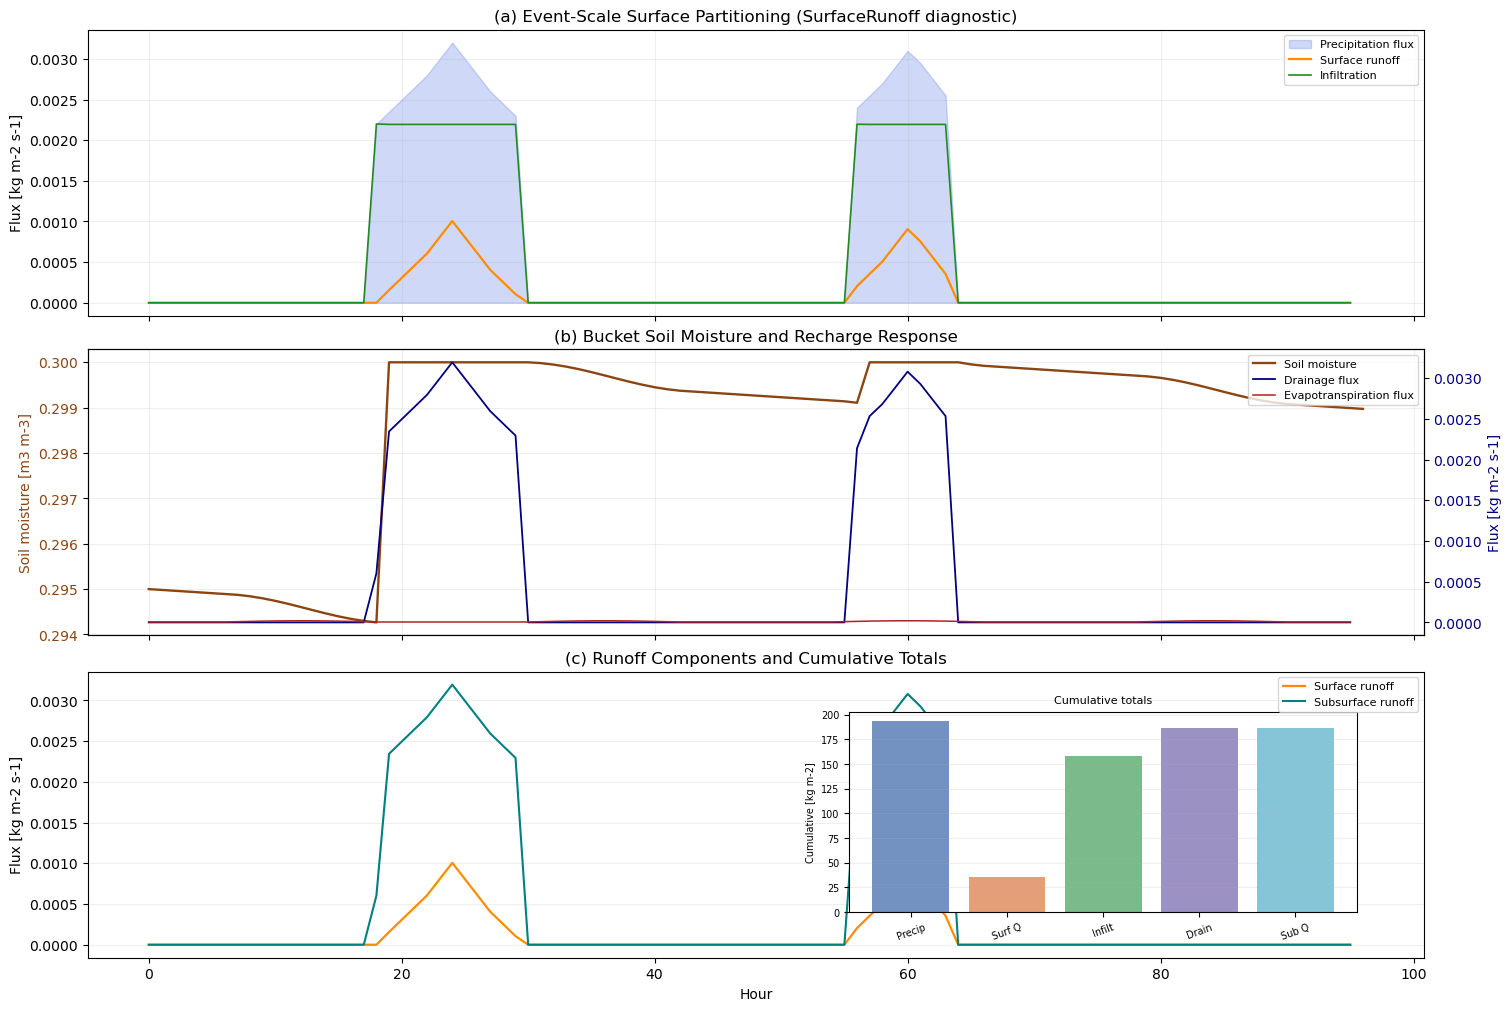

[OK] Runoff diagnostics checked: surface_runoff_max=0.001006, subsurface_runoff_max=0.003195, soil_moisture_range=(0.294, 0.300)
[OK] Cumulative totals [kg m-2]: Precip=193.50, Surf Q=35.47, Infilt=158.03, Drain=186.16, Sub Q=186.16


In [13]:
# === Surface & Subsurface Runoff via RELIC Modules ===
# References:
# - SCS (1972) curve number; Horton (1933) infiltration excess; Dunne and Black (1970) saturation excess.
# - Brutsaert and Nieber (1977); Tallaksen (1995) baseflow recession; Manabe (1969) bucket.
# - RELIC implementations: runoff/surface.py, runoff/subsurface.py, soil_moisture/bucket.py.
# Mathematical expression:
# - Q_surface = min(P, max(Q_SCS, Q_Horton, Q_sat)); infiltration = P - Q_surface (SurfaceRunoff)
# - theta(t + dt), D_b = BucketSoilMoisture.forward(theta, P, ET) (the bucket receives the full P)
# - S* = min(S + D_b * dt, S_max); V = min((k * S* + Q_i) * dt, S*); Q_sub = (V + overflow) / dt (SubsurfaceRunoff)
# Parameter meanings:
# - P: storm precipitation; ET: prescribed evapotranspiration; theta: bucket soil moisture.
# - D_b: bucket drainage used as recharge; S: groundwater storage; S_max: capacity; k: recession constant; Q_i: interflow.
# Units:
# - fluxes [kg m-2 s-1]; theta [m3 m-3]; S [mm]; k [s-1]; dt [s]; cumulative totals [kg m-2].
# Domain/constraints:
# - SurfaceRunoff and the bucket are evaluated independently on the same P, so the surface partition is a
#   side diagnostic and the cumulative bars are component totals, not a closed budget.
# Sign convention:
# - P enters the surface; runoff, drainage and subsurface runoff are positive exports.

import torch
import matplotlib.pyplot as plt
from IPython.display import display

from relic.scientific.hydrosphere.runoff.surface import SurfaceRunoff
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture

surface_runoff_functor = SurfaceRunoff(name="tutorial_surface_runoff_real")
subsurface_runoff_functor = SubsurfaceRunoff(name="tutorial_subsurface_runoff_event_real")
bucket_functor = BucketSoilMoisture(name="tutorial_bucket_event_real")

n_hours = 96
dt_hour = 3600.0
hours = torch.arange(n_hours, dtype=torch.float32)
precipitation_flux_series = torch.zeros(n_hours, dtype=torch.float32)
storm_one = torch.tensor([0.0022, 0.00235, 0.0025, 0.00265, 0.0028, 0.0030, 0.0032, 0.0030, 0.0028, 0.0026, 0.00245, 0.0023], dtype=torch.float32)
storm_two = torch.tensor([0.0024, 0.00255, 0.0027, 0.0029, 0.0031, 0.00295, 0.00275, 0.00255], dtype=torch.float32)
precipitation_flux_series[18:30] = storm_one
precipitation_flux_series[56:64] = storm_two

evapotranspiration_flux_series = 0.000005 + 0.000015 * torch.clamp(
    torch.sin(2.0 * torch.pi * (hours - 6.0) / 24.0),
    min=0.0,
)
air_temperature_series = 292.15 + 2.5 * torch.sin(2.0 * torch.pi * (hours - 4.0) / 24.0)
soil_moisture = torch.tensor(0.295, dtype=torch.float32)
groundwater_storage = torch.tensor(0.0, dtype=torch.float32)

soil_moisture_history = [soil_moisture.detach().clone()]
surface_runoff_history = []
infiltration_history = []
drainage_history = []
subsurface_runoff_history = []

for hour_idx in range(n_hours):
    precipitation_flux = precipitation_flux_series[hour_idx]
    evapotranspiration_flux = evapotranspiration_flux_series[hour_idx]

    surface_updates = surface_runoff_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux,
        },
        time=float(hour_idx) * dt_hour,
        dt=dt_hour,
    )
    surface_runoff_flux = unwrap_update(surface_updates["surface_runoff_flux"]).detach().to(dtype=torch.float32)
    infiltration_flux = unwrap_update(surface_updates["infiltration_flux"]).detach().to(dtype=torch.float32)

    bucket_updates = bucket_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "precipitation_flux": precipitation_flux,
            "evapotranspiration_flux": evapotranspiration_flux,
            "air_temperature": air_temperature_series[hour_idx],
        },
        time=float(hour_idx) * dt_hour,
        dt=dt_hour,
    )
    soil_moisture = unwrap_update(bucket_updates["soil_moisture"]).detach().to(dtype=torch.float32)
    drainage_flux = unwrap_update(bucket_updates["drainage_flux"]).detach().to(dtype=torch.float32)

    subsurface_updates = subsurface_runoff_functor.forward(
        {
            "soil_moisture": soil_moisture,
            "groundwater_storage": groundwater_storage,
            "drainage_flux": drainage_flux,
        },
        time=float(hour_idx) * dt_hour,
        dt=dt_hour,
    )
    groundwater_storage = unwrap_update(subsurface_updates["groundwater_storage"]).detach().to(dtype=torch.float32)
    subsurface_runoff_flux = unwrap_update(subsurface_updates["subsurface_runoff_flux"]).detach().to(dtype=torch.float32)

    soil_moisture_history.append(soil_moisture.detach().clone())
    surface_runoff_history.append(surface_runoff_flux.detach().clone())
    infiltration_history.append(infiltration_flux.detach().clone())
    drainage_history.append(drainage_flux.detach().clone())
    subsurface_runoff_history.append(subsurface_runoff_flux.detach().clone())

soil_moisture_history = torch.stack(soil_moisture_history)
surface_runoff_history = torch.stack(surface_runoff_history)
infiltration_history = torch.stack(infiltration_history)
drainage_history = torch.stack(drainage_history)
subsurface_runoff_history = torch.stack(subsurface_runoff_history)

cumulative_components = torch.stack(
    [
        torch.sum(precipitation_flux_series * dt_hour),
        torch.sum(surface_runoff_history * dt_hour),
        torch.sum(infiltration_history * dt_hour),
        torch.sum(drainage_history * dt_hour),
        torch.sum(subsurface_runoff_history * dt_hour),
    ]
)

time_axis = hours.tolist()
state_time_axis = torch.arange(n_hours + 1, dtype=torch.float32).tolist()

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True, constrained_layout=True)

axes[0].fill_between(time_axis, [0.0] * n_hours, precipitation_flux_series.tolist(), color="royalblue", alpha=0.25, label="Precipitation flux")
axes[0].plot(time_axis, surface_runoff_history.tolist(), color="darkorange", lw=1.6, label="Surface runoff")
axes[0].plot(time_axis, infiltration_history.tolist(), color="forestgreen", lw=1.2, label="Infiltration")
axes[0].set_ylabel("Flux [kg m-2 s-1]")
axes[0].set_title("(a) Event-Scale Surface Partitioning (SurfaceRunoff diagnostic)")
axes[0].legend(fontsize=8, loc="upper right")
axes[0].grid(True, alpha=0.2)

state_ax = axes[1]
flux_ax = state_ax.twinx()
state_ax.plot(state_time_axis, soil_moisture_history.tolist(), color="saddlebrown", lw=1.7, label="Soil moisture")
flux_ax.plot(time_axis, drainage_history.tolist(), color="navy", lw=1.3, label="Drainage flux")
flux_ax.plot(time_axis, evapotranspiration_flux_series.tolist(), color="firebrick", lw=1.1, label="Evapotranspiration flux")
state_ax.set_ylabel("Soil moisture [m3 m-3]", color="saddlebrown")
flux_ax.set_ylabel("Flux [kg m-2 s-1]", color="navy")
state_ax.tick_params(axis="y", labelcolor="saddlebrown")
flux_ax.tick_params(axis="y", labelcolor="navy")
state_ax.set_title("(b) Bucket Soil Moisture and Recharge Response")
state_ax.grid(True, alpha=0.2)
state_handles, state_labels = state_ax.get_legend_handles_labels()
flux_handles, flux_labels = flux_ax.get_legend_handles_labels()
state_ax.legend(state_handles + flux_handles, state_labels + flux_labels, fontsize=8, loc="upper right")

axes[2].plot(time_axis, surface_runoff_history.tolist(), color="darkorange", lw=1.6, label="Surface runoff")
axes[2].plot(time_axis, subsurface_runoff_history.tolist(), color="teal", lw=1.5, label="Subsurface runoff")
axes[2].set_title("(c) Runoff Components and Cumulative Totals")
axes[2].set_ylabel("Flux [kg m-2 s-1]")
axes[2].set_xlabel("Hour")
axes[2].grid(True, axis="y", alpha=0.2)
axes[2].legend(fontsize=8, loc="upper right")

inset_ax = axes[2].inset_axes([0.57, 0.16, 0.38, 0.70])
short_labels = ["Precip", "Surf Q", "Infilt", "Drain", "Sub Q"]
bar_colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2", "#64B5CD"]
bar_positions = list(range(len(short_labels)))
inset_ax.bar(bar_positions, cumulative_components.tolist(), color=bar_colors, alpha=0.78)
inset_ax.set_xticks(bar_positions)
inset_ax.set_xticklabels(short_labels)
inset_ax.set_ylabel("Cumulative [kg m-2]", fontsize=7)
inset_ax.tick_params(axis="x", rotation=20, labelsize=7)
inset_ax.tick_params(axis="y", labelsize=7)
inset_ax.set_title("Cumulative totals", fontsize=8)
inset_ax.grid(True, axis="y", alpha=0.2)

display(plt.gcf())
plt.close(plt.gcf())
print(
    f"[OK] Runoff diagnostics checked: surface_runoff_max={float(torch.max(surface_runoff_history)):.6f}, "
    f"subsurface_runoff_max={float(torch.max(subsurface_runoff_history)):.6f}, "
    f"soil_moisture_range=({float(torch.min(soil_moisture_history)):.3f}, {float(torch.max(soil_moisture_history)):.3f})"
)
print(
    "[OK] Cumulative totals [kg m-2]: "
    + ", ".join(f"{label}={float(value):.2f}" for label, value in zip(short_labels, cumulative_components))
)

## Summary

This notebook called the `forward` kernels of actual RELIC Functors:
- `BucketSoilMoisture`: sequential partition into ET, saturation-excess runoff and drainage above field capacity, with the bucket water budget closed over 168 hours
- `FirstOrderDecomposition`: five-pool first-order decomposition with a $Q_{10}$ = 2 temperature response; `CarbonPoolsFunctor` as a state-neutral pool observer
- Isotopes: candidate configuration and fractionation calculators; the runtime stays fail-closed (`[N] runtime_unbound`)
- `FickianDiffusion`: mass-conserving explicit diffusion of a Gaussian pulse and its stability number
- `SnowPack` and `SnowAlbedo` (BATS scheme), `PenmanMonteithET` (`canopy_resistance_source="state"`) and `PriestleyTaylorET`
- `VerticalPercolationTransport` (van Genuchten-Mualem conductivity) with `SubsurfaceRunoff`, and `SurfaceRunoff` with the bucket

The Richards solver, capillary rise, groundwater dynamics and pedosphere solute transport were described by their equations only.

**Next:** Proceed to **NB06** for spatiotemporal scale topology.